# Avance Fase 3 — Semana 2
## Núcleo algorítmico, eficiencia y programación orientada a objetos
**Pertenencia al SNSS y nivel de complejidad de los establecimientos de salud en Chile**

**Grupo 1:** Brian Cerda · Kattia Espinoza · Karla Martínez · Christopher Ulloa

---

En la Fase 2 construimos un pipeline que funciona: ocho filtros explícitos llevan el registro de 5.837 filas a una
población de 4.603 establecimientos, y una codificación One-Hot produce la matriz 0/1. En esta fase tomamos **ese mismo
pipeline** y le damos forma de sistema: las mismas operaciones, ahora organizadas en módulos y clases que se pueden
probar, reemplazar y reutilizar, y con su costo medido.

No hay datos nuevos ni reglas nuevas. **Lo que cambia es la arquitectura del código.** La prueba de que la
reorganización está bien hecha es que las salidas de la Fase 3 son idénticas a las de la Fase 2, lo que comprobamos en
la sección 11 y nuevamente al cierre.

**Cambio de la Fase 4.** `Transformador` pasó a ser una clase abstracta con el módulo `abc` (sección 3) y se agregaron
dos pruebas que lo comprueban (sección 13.4). Las salidas de esta fase no cambian.

**Cómo está construido este cuaderno.** El código vive en la carpeta `src/` y aquí se **importa**, no se copia. Cuando
conviene leer una clase o una función, la mostramos con `mostrar_codigo`, que imprime el código fuente directamente
desde el módulo. Así existe una sola versión de cada pieza: la que se ejecuta es la misma que se lee.

### Recorrido

| Parte | Contenido | Qué evidencia |
|---|---|---|
| 0 | Configuración, entorno y carga | Código en módulos, importado |
| 1 | El conjunto antes de tocarlo | Preprocesamiento |
| 2 | Punto de partida: el flujo de la Fase 2 | Evolución del código |
| 3 | ¿Función o clase? La clase base `Transformador` | Programación orientada a objetos |
| 4 | Funciones sin estado, su adaptador y el encapsulamiento | Programación orientada a objetos |
| 5 | Herencia en dos niveles: `Filtro` y sus hijas | Programación orientada a objetos |
| 6 | Codificación | Preprocesamiento |
| 7 | `Pipeline` y polimorfismo | Diseño estructurado |
| 8 | Patrón Observer: bitácora, exclusiones y tiempos | Patrones de diseño |
| 9 | Patrón Factory: el pipeline desde la configuración | Patrones de diseño |
| 10 | `PreprocesadorRegistro`: el pipeline completo en una llamada | Preprocesamiento |
| 11 | Verificación: ¿produce el mismo resultado que la Fase 2? | Validación técnica |
| 12 | Cohesión y acoplamiento | Diseño estructurado |
| 13 | Validación: casos normales, límite y excepciones | Validación técnica |
| 14 | Recursividad | Diseño estructurado |
| 15 | Eficiencia: tiempo, memoria y decisiones | Eficiencia y optimización |
| 16 | Bitácora de decisiones de diseño | Documentación de arquitectura |
| 17 | Arquitectura generada desde el código | Documentación de arquitectura |
| 18 | Persistencia y verificación final contra la Fase 2 | Trazabilidad |
| 19 | Conclusiones y proyección a la Fase 4 | Síntesis |

**Integración con las fases anteriores.** El cuaderno lee la definición del estudio que dejó la Fase 1
(`docs/proyecto.json`), la huella del archivo (`docs/metadatos_f1.json`) y las salidas de la Fase 2
(`data/processed/` y `docs/`), y reutiliza las funciones de `src/utilidades.py` que ya usaban ambas fases. Las técnicas
de medición del avance formativo (`timeit` y `tracemalloc`) se aplican aquí a una operación real de nuestro pipeline.
Para ejecutarlo, primero deben haberse ejecutado los cuadernos de F1 y F2.

---
## 0. Configuración del proyecto
Esta celda ubica la raíz del proyecto, habilita la importación de `src/` y carga la configuración. Las reglas que
definen la población son las mismas ocho de la Fase 2 (F01 a F08), pero ahora están **declaradas como datos** en
`src/configuracion.py` y no escritas como llamadas dentro del flujo. Más adelante, en la sección 9, el pipeline se
construye a partir de ellas.

La única función que se define aquí es `localizar_raiz`, porque hace falta antes de poder importar cualquier módulo.

In [1]:
import json
import sys
from pathlib import Path


def localizar_raiz(inicio=None):
    """Devuelve la raíz del proyecto aunque el cuaderno se abra desde una carpeta de fase."""
    inicio = Path.cwd() if inicio is None else Path(inicio)
    return inicio.parent if inicio.name in {"F1", "F2", "F3"} else inicio


RAIZ = localizar_raiz()
if str(RAIZ) not in sys.path:                # permite importar src/ y tests/ desde la carpeta F3
    sys.path.insert(0, str(RAIZ))

from src.configuracion import (CODIFICACIONES, COLUMNAS_AUDITORIA, COLUMNAS_NECESARIAS, COLUMNAS_NUMERICAS,
                               COLUMNAS_POBLACION, ESTADOS_VIGENTES, MAPA_PERTENENCIA, NORMALIZACIONES,
                               ORDEN_COMPLEJIDAD, ORDEN_GRUPOS, PASOS_COMPLEJIDAD, REGLAS_POBLACION,
                               crear_configuracion)

PROYECTO = json.loads((RAIZ / "docs/proyecto.json").read_text(encoding="utf-8"))       # definición de la Fase 1
METADATOS_F1 = json.loads((RAIZ / "docs/metadatos_f1.json").read_text(encoding="utf-8"))
RUTA_DATOS = RAIZ / "data/raw" / PROYECTO["fuente"]["archivo"]
DIR_PROCESADO = RAIZ / "data/processed"          # salidas de la Fase 2 (no se sobrescriben)
DIR_SALIDA_F3 = RAIZ / "data/processed/f3"       # salidas de esta fase
DIR_DOCS_F3 = RAIZ / "docs/f3"
DIR_FIGURAS_F3 = DIR_DOCS_F3 / "figuras"
SEMILLA = 42

# La configuración de la Fase 3 debe coincidir con las categorías definidas en la Fase 1
dimensiones = PROYECTO["dimensiones"]["principales"]
assert ORDEN_GRUPOS == dimensiones[0]["categorias"], "Las categorías de pertenencia no coinciden con F1"
assert ORDEN_COMPLEJIDAD == dimensiones[1]["categorias"], "Los niveles de complejidad no coinciden con F1"

print("Carpeta del proyecto:", RAIZ.resolve().name)
print("Archivo de entrada  :", RUTA_DATOS.relative_to(RAIZ).as_posix())
print("Matriz 0/1          :", COLUMNAS_NUMERICAS)
print("\nReglas de la población declaradas en src/configuracion.py:")
for regla in REGLAS_POBLACION:
    print(f"  {regla['paso']}  {regla['tipo']:<21} {regla['motivo']}")

Carpeta del proyecto: repo
Archivo de entrada  : data/raw/establecimientos_20261103.csv
Matriz 0/1          : ['snss_perteneciente', 'snss_no_perteneciente', 'complejidad_baja', 'complejidad_mediana', 'complejidad_alta']

Reglas de la población declaradas en src/configuracion.py:
  F01  permitidos            Conservar estado vigente
  F02  informado             Código informado
  F03  duplicados_exactos    Una copia de filas exactamente repetidas
  F04  codigos_en_conflicto  Excluir códigos con registros distintos en conflicto
  F05  permitidos            Pertenencia clasificable: excluir No Aplica, vacíos o no reconocidos
  F06  informado             Complejidad informada: excluir vacíos
  F07  excluir_valor         Complejidad aplicable: excluir No Aplica
  F08  permitidos            Complejidad reconocida: Baja, Mediana o Alta


**Qué obtuvimos.** La raíz se localiza aunque el cuaderno se abra desde la carpeta `F3`, y las dos comprobaciones con
`assert` confirman que las categorías que usa esta fase (SNSS y No SNSS; Baja, Mediana y Alta) son las mismas que
definimos en la Fase 1. La lista muestra las ocho reglas con su tipo: ese tipo es el que más adelante decide qué clase
de filtro se construye para cada una. Las salidas de esta fase irán a `data/processed/f3` y `docs/f3`, de modo que los
archivos de la Fase 2 quedan intactos y podemos comparar contra ellos.

## Preparación del entorno
Importamos las bibliotecas y definimos `mostrar_codigo`, la utilidad con la que este cuaderno enseña el código de
`src/` sin duplicarlo. También fijamos el estilo de los gráficos de la sección 15. La semilla queda declarada aunque el
preprocesamiento no tiene pasos aleatorios: solo se usa para tomar las muestras de la medición de eficiencia.

In [2]:
import inspect
import io
import platform
import unittest
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 80)
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
COLORES = ["#008A9E", "#D98E1F", "#7353A6"]


def mostrar_codigo(*objetos):
    """Muestra el código fuente de funciones o clases de src/ sin copiarlo al cuaderno."""
    fuente = "\n\n\n".join(inspect.getsource(objeto).rstrip() for objeto in objetos)
    display(Markdown(f"```python\n{fuente}\n```"))


print("Python    :", platform.python_version())
print("pandas    :", pd.__version__)
print("NumPy     :", np.__version__)
print("Semilla   :", SEMILLA)

Python    : 3.13.18
pandas    : 3.0.5
NumPy     : 2.5.2
Semilla   : 42


**Qué obtuvimos.** El cuaderno usa solo pandas, NumPy, Matplotlib y la biblioteca estándar, todas declaradas en
`requirements.txt` con versión fija: la Fase 3 no agrega dependencias nuevas. Las versiones que se imprimen deben
coincidir con las de ese archivo, que el cuaderno de la Fase 1 compara contra el entorno activo.

## Carga del conjunto desde el archivo externo
La carga hace tres cosas antes de entregar los datos: lee el CSV como texto, para no alterar códigos ni convertir
«No Aplica» en faltante; comprueba que la huella SHA-256 del archivo coincida con la que registró la Fase 1; y verifica
que estén las columnas que el pipeline necesita. La función está en `src/carga.py`.

In [3]:
from src.carga import cargar_registro

mostrar_codigo(cargar_registro)

datos = cargar_registro(RUTA_DATOS, COLUMNAS_NECESARIAS, METADATOS_F1["sha256"])
print(f"Forma: {datos.shape[0]} filas x {datos.shape[1]} columnas")
print("Huella SHA-256 idéntica a la registrada en la Fase 1")
datos[COLUMNAS_NECESARIAS].head(3)

```python
def cargar_registro(ruta, columnas_esperadas, huella_esperada=None):
    """Lee el CSV como texto, verifica su huella y comprueba el esquema."""
    datos = cargar_datos(ruta)
    if huella_esperada is not None and huella_archivo(ruta) != huella_esperada:
        raise ValueError("La huella del archivo no coincide con la registrada en F1.")
    faltantes = [c for c in columnas_esperadas if c not in datos.columns]
    if faltantes:
        raise KeyError(f"Faltan columnas en el archivo: {faltantes}")
    return datos
```

Forma: 5837 filas x 33 columnas
Huella SHA-256 idéntica a la registrada en la Fase 1


,EstablecimientoCodigo,EstadoFuncionamiento,TipoPertenenciaEstabGlosa,NivelComplejidadEstabGlosa
0,101011,Vigente en Operación Habitual,Perteneciente al Sistema Nacional de Servicios de Salud,Baja Complejidad
1,200601,Vigente en Operación Habitual,Perteneciente al Sistema Nacional de Servicios de Salud,Mediana Complejidad
2,101608,Vigente en Operación Habitual,Perteneciente al Sistema Nacional de Servicios de Salud,Mediana Complejidad


**Qué obtuvimos.** El archivo se leyó completo, con 5.837 filas y 33 columnas, y es exactamente el mismo que usaron
las Fases 1 y 2. Si la huella no coincidiera, la carga se detendría con un `ValueError` antes de procesar nada, y si
faltara una columna necesaria, con un `KeyError`: preferimos un error visible al inicio que un resultado distinto sin
explicación al final.

---
## 1. El conjunto antes de tocarlo
Antes de reorganizar el código conviene recordar con qué datos trabaja. Calculamos un perfil breve de las cuatro
columnas que usa el pipeline: cuántos vacíos y cuántos «No Aplica» tienen, y cuántas variantes de escritura
desaparecen al normalizar espacios y mayúsculas. La función `perfilar` está en `src/descripcion.py`.

In [4]:
from src.descripcion import perfilar

perfil = perfilar(datos, COLUMNAS_NECESARIAS)
display(perfil)
print("Estados de funcionamiento:")
print(datos["EstadoFuncionamiento"].value_counts().to_string())

,columna,vacios,no_aplica,variantes_originales,variantes_normalizadas
0,EstablecimientoCodigo,0,0,5837,5837
1,EstadoFuncionamiento,0,0,3,2
2,TipoPertenenciaEstabGlosa,0,41,4,3
3,NivelComplejidadEstabGlosa,288,768,5,5


Estados de funcionamiento:
EstadoFuncionamiento
Vigente en Operación Habitual    5271
Cerrado                           431
Vigente en operación habitual     135


**Qué obtuvimos.** El perfil muestra tres hechos que condicionan el diseño:

1. **Hay 431 establecimientos cerrados y dos escrituras del estado vigente** («Operación Habitual» y «operación
   habitual»). Por eso hay que normalizar el texto antes de filtrar: de tres variantes quedan dos categorías.
2. **«No Aplica» no es un vacío.** Es una etiqueta que viene de la fuente (41 casos en pertenencia y 768 en
   complejidad) y es distinta de los 288 vacíos de complejidad. Ninguno se imputa: se excluyen, cada uno con su motivo.
3. **El código vigente no tiene vacíos ni repeticiones.** Aun así el pipeline debe comprobarlo (reglas F02 a F04),
   porque un nuevo corte del registro podría traerlos.

---
## 2. Punto de partida: el flujo de la Fase 2
Este es el código del que partimos. En la Fase 2 el preprocesamiento estaba repartido en celdas; aquí aparece reunido
en una función, `flujo_f2`, que conserva las mismas reglas, el mismo orden y las mismas salidas. La guardamos en
`src/referencia_f2.py` **solo como línea base**: nos sirve para comprobar que la nueva arquitectura da el mismo
resultado (sección 11) y para medir cuánto cuesta (sección 15). El proyecto no la usa para generar sus salidas.

Mostramos `aplicar_filtro`, que es la pieza que más cambia en esta fase, y ejecutamos el flujo completo.

In [5]:
from src.referencia_f2 import aplicar_filtro, flujo_f2

mostrar_codigo(aplicar_filtro)

referencia_f2 = flujo_f2(datos)
print("Población de referencia:", referencia_f2["poblacion"].shape)
print("Matriz de referencia   :", referencia_f2["matriz"].shape)
print("Llamadas a aplicar_filtro dentro de flujo_f2:", inspect.getsource(flujo_f2).count("aplicar_filtro("))

```python
def aplicar_filtro(datos, condicion, paso, motivo, bitacora, exclusiones):
    """Filtra filas y registra su primer motivo de exclusión en las listas recibidas."""
    condicion = condicion.fillna(False)
    excluidos = datos.loc[~condicion].copy()
    excluidos["paso_exclusion"] = paso
    excluidos["motivo_exclusion"] = motivo
    exclusiones.append(excluidos)
    restantes = datos.loc[condicion].copy()
    bitacora.append({"paso": paso, "regla": motivo, "antes": len(datos),
                     "excluidos": len(excluidos), "restantes": len(restantes)})
    return restantes
```

Población de referencia: (4603, 5)
Matriz de referencia   : (4603, 5)
Llamadas a aplicar_filtro dentro de flujo_f2: 8


**Qué obtuvimos.** El flujo funciona y produce los 4.603 establecimientos y la matriz de 4.603 × 5 de la Fase 2. Pero
al revisarlo como grupo identificamos cuatro problemas que aparecen cuando el proyecto crece:

| Problema | Consecuencia |
|---|---|
| Cada regla está escrita a mano como una llamada distinta (ocho llamadas) | Agregar o cambiar una regla obliga a editar la función |
| `aplicar_filtro` recibe seis argumentos, y dos de ellos son listas que modifica | La bitácora y las exclusiones dependen de que cada llamada pase las mismas listas: el acoplamiento es alto |
| No se puede probar un paso por separado | Si el resultado está mal, hay que revisar el flujo completo |
| Lo que el flujo «aprende» (valores sin correspondencia, códigos en conflicto) no queda guardado | No hay forma de aplicar las mismas reglas a un nuevo corte del registro ni de auditar qué se aprendió |

Las secciones siguientes resuelven los cuatro: cada paso pasa a ser una pieza con nombre, con una interfaz fija y, cuando
hace falta, con estado propio.

---
## 3. ¿Función o clase? La clase base `Transformador`
Antes de escribir clases decidimos **cuáles componentes las necesitan**. El criterio que seguimos fue uno solo: una
clase se justifica cuando el componente necesita **recordar algo entre una llamada y otra**. Si no recuerda nada, es
una función.

| Componente del pipeline | ¿Qué recuerda entre llamadas? | Forma elegida |
|---|---|---|
| Agregar la fila de origen | Nada | Función |
| Normalizar el texto de una columna | Nada | Función |
| Seleccionar columnas | Nada | Función |
| Traducir a categorías analíticas | Los valores observados y los que no tienen correspondencia | Clase `MapeadorCategorias` |
| Filtrar (reglas F01 a F08) | Las filas que excluyó, con su paso y motivo; los códigos en conflicto | Clases `Filtro` y sus hijas |
| Codificar en 0/1 | El vocabulario declarado y las categorías que observó | Clase `CodificadorBinario` |
| Contingencia, retención, perfil | Nada | Funciones |

Las clases comparten una **clase base**, `Transformador`, que escribe una sola vez lo que todas tienen en común:

- **Encapsulamiento:** `_parametros` y `_ajustado` son internos (llevan guion bajo) y solo se exponen mediante
  propiedades de lectura; `parametros` entrega una copia.
- **Control de estado:** `transformar` falla si el paso no se ajustó antes, y valida las columnas antes de actuar.
- **Contrato:** `Transformador` es una **clase abstracta** (hereda de `ABC`, del módulo `abc`) y declara `aprender`
  (qué aprende) y `aplicar` (cómo lo aplica) con `@abstractmethod`: cada clase hija debe implementarlos.
- **Copia defensiva:** `transformar` trabaja sobre una copia; la tabla de entrada nunca se modifica.

In [6]:
from src.transformadores import Transformador

mostrar_codigo(Transformador)

# --- CAMBIO (Fase 4: clase base abstracta) ---
# ANTES:    Transformador("EstadoFuncionamiento").ajustar(datos) fallaba con NotImplementedError, recién al ajustar.
# AHORA:    Transformador hereda de ABC; Python no deja crearlo y responde con TypeError al instanciar.
# try:
#     Transformador("EstadoFuncionamiento").ajustar(datos)
# except NotImplementedError as error:
#     print("NotImplementedError:", error)

# La clase base no se usa sola: define el contrato que deben cumplir las hijas
import inspect
print("¿Es abstracta?     :", inspect.isabstract(Transformador))
print("Métodos abstractos :", sorted(Transformador.__abstractmethods__))
try:
    Transformador("EstadoFuncionamiento")
except TypeError as error:
    print("TypeError:", error)

```python
class Transformador(ABC):
    """Clase base abstracta: contrato común y control de estado de cada paso del pipeline."""

    def __init__(self, columnas=()):
        # Atributo público: las columnas sobre las que trabaja el paso
        self.columnas = [columnas] if isinstance(columnas, str) else list(columnas)
        # Atributos internos (guion bajo): se aprenden, no se asignan desde fuera
        self._parametros = {}
        self._ajustado = False

    @property
    def nombre(self):
        """Nombre legible del paso, con la clase real del objeto."""
        detalle = ", ".join(self.columnas[:2]) + ("…" if len(self.columnas) > 2 else "")
        return f"{type(self).__name__}({detalle})"

    @property
    def parametros(self):
        """Copia defensiva de lo aprendido: no permite modificar el estado interno."""
        return dict(self._parametros)

    @property
    def ajustado(self):
        """Solo lectura: indica si el paso ya aprendió sus parámetros."""
        return self._ajustado

    def _validar_columnas(self, df):
        faltantes = [c for c in self.columnas if c not in df.columns]
        if faltantes:
            raise KeyError(f"{self.nombre}: faltan columnas en el conjunto: {faltantes}")

    def ajustar(self, df):
        """Valida la entrada, aprende los parámetros y marca el paso como ajustado."""
        self._validar_columnas(df)
        self._parametros = self.aprender(df)
        self._ajustado = True
        return self

    def transformar(self, df):
        """Aplica lo aprendido sobre una copia: nunca modifica la entrada."""
        if not self._ajustado:
            raise RuntimeError(f"{self.nombre}: hay que ajustar antes de transformar.")
        self._validar_columnas(df)
        return self.aplicar(df.copy())

    def ajustar_transformar(self, df):
        """Atajo para aprender y aplicar sobre el mismo conjunto."""
        return self.ajustar(df).transformar(df)

    @abstractmethod
    def aprender(self, df):
        """Devuelve, como diccionario, lo que el paso aprende del conjunto. Cada clase hija lo implementa."""
        raise NotImplementedError("Cada clase hija debe implementar aprender().")

    @abstractmethod
    def aplicar(self, df):
        """Aplica lo aprendido y devuelve el conjunto transformado. Cada clase hija lo implementa."""
        raise NotImplementedError("Cada clase hija debe implementar aplicar().")
```

¿Es abstracta?     : True
Métodos abstractos : ['aplicar', 'aprender']
TypeError: Can't instantiate abstract class Transformador without an implementation for abstract methods 'aplicar', 'aprender'


**Qué obtuvimos.** La clase base no puede usarse directamente. Como es abstracta, Python no permite ni siquiera crearla:
responde con `TypeError` y nombra los métodos que faltan, `aplicar` y `aprender`. Lo mismo pasa con una clase hija que
olvide implementar alguno, así que el error aparece al escribir el paso y no a mitad del pipeline. A cambio, el control de
estado, la validación de columnas y la copia defensiva quedan escritos una sola vez y todas las clases hijas los heredan.

**¿Por qué separar `ajustar` de `transformar` si no hay un modelo predictivo?** Nuestro proyecto describe una población
completa y no separa entrenamiento y prueba, así que no hay fuga de datos que evitar. La separación nos sirve igual: lo
aprendido sobre este corte del registro queda guardado y puede aplicarse sin cambios a un corte nuevo, como probamos en
la sección 13.

---
## 4. Funciones sin estado, su adaptador y la primera clase hija
Normalizar texto no aprende nada: recibe una tabla y devuelve otra. Por eso `normalizar_columna` sigue siendo una
**función** (`src/funciones.py`). Para que el pipeline pueda recorrer funciones y clases de la misma manera usamos un
adaptador pequeño, `PasoFuncion`, que hereda de `Transformador` y solo guarda qué función aplicar y con qué argumentos.

La traducción a categorías analíticas, en cambio, sí recuerda algo: `MapeadorCategorias` aprende qué valores observó y
cuáles **no tienen correspondencia**. Esa información antes había que buscarla a mano en la Fase 2.

In [7]:
from src.funciones import normalizar_columna
from src.transformadores import MapeadorCategorias, PasoFuncion

mostrar_codigo(normalizar_columna, PasoFuncion, MapeadorCategorias)

# Una función adaptada: no aprende nada
paso_estado = PasoFuncion(normalizar_columna, columna="EstadoFuncionamiento", destino="estado_normalizado")
con_estado = paso_estado.ajustar_transformar(datos)
print(paso_estado.nombre, "-> parámetros aprendidos:", paso_estado.parametros)
print("Variantes del estado:", datos["EstadoFuncionamiento"].nunique(), "->", con_estado["estado_normalizado"].nunique())

# Una clase: aprende qué valores quedaron sin correspondencia
paso_pertenencia = PasoFuncion(normalizar_columna, columna="TipoPertenenciaEstabGlosa",
                               destino="pertenencia_original_normalizada")
mapeador = MapeadorCategorias("pertenencia_original_normalizada", "pertenencia_snss", MAPA_PERTENENCIA)
con_pertenencia = mapeador.ajustar_transformar(paso_pertenencia.ajustar_transformar(datos))
print("\n" + mapeador.nombre, "-> sin correspondencia:", mapeador.parametros["sin_correspondencia"])
print(con_pertenencia["pertenencia_snss"].value_counts(dropna=False).to_string())

```python
def normalizar_columna(df, columna, destino):
    """Unifica espacios y mayúsculas de una columna y guarda el resultado en otra."""
    return df.assign(**{destino: normalizar_texto(df[columna])})


class PasoFuncion(Transformador):
    """Adapta una función sin estado al contrato del pipeline.

    No aprende nada de los datos: solo guarda qué función aplicar y con qué
    argumentos, para que el pipeline trate igual a funciones y clases.
    """

    def __init__(self, funcion, **argumentos):
        super().__init__(argumentos.get("columna", ()))
        self.funcion = funcion
        self.argumentos = argumentos

    @property
    def nombre(self):
        if "columnas" in self.argumentos:
            detalle = f"{len(self.argumentos['columnas'])} columnas"
        else:
            detalle = self.argumentos.get("columna", "")
        return f"{self.funcion.__name__}({detalle})"

    def aprender(self, df):
        return {}

    def aplicar(self, df):
        return self.funcion(df, **self.argumentos)


class MapeadorCategorias(Transformador):
    """Traduce etiquetas normalizadas a categorías analíticas con un mapeo explícito.

    Aprende qué valores observó y cuáles no tienen correspondencia. Esos valores
    quedan como faltantes: no se imputan, los excluyen después los filtros con su motivo.
    """

    def __init__(self, columna, destino, correspondencias):
        super().__init__(columna)
        self.destino = destino
        self.correspondencias = dict(correspondencias)

    def aprender(self, df):
        observadas = sorted(df[self.columnas[0]].dropna().unique())
        return {"observadas": observadas,
                "sin_correspondencia": [v for v in observadas if v not in self.correspondencias]}

    def aplicar(self, df):
        df[self.destino] = df[self.columnas[0]].map(self.correspondencias)
        return df
```

normalizar_columna(EstadoFuncionamiento) -> parámetros aprendidos: {}
Variantes del estado: 3 -> 2

MapeadorCategorias(pertenencia_original_normalizada) -> sin correspondencia: ['no aplica']
pertenencia_snss
SNSS       3288
No SNSS    2508
NaN          41


**Qué obtuvimos.** La función adaptada reduce las tres escrituras del estado a dos categorías y su diccionario de
parámetros está vacío, lo que confirma que no aprende nada: es coherente con haberla dejado como función. El mapeador,
en cambio, dejó registrado que `no aplica` no tiene correspondencia. Esos 41 registros quedan como faltantes en
`pertenencia_snss` para que más adelante los excluya la regla F05 con su motivo; no se imputan ni se asignan a ninguna
categoría. El conteo resultante coincide con el de la Fase 2: 3.288 SNSS, 2.508 No SNSS y 41 sin correspondencia.

### El encapsulamiento en acción
Comprobamos tres comportamientos que protegen el estado interno de las clases: transformar antes de ajustar debe
fallar con un mensaje claro; la propiedad `ajustado` no debe poder asignarse desde fuera; y `parametros` debe entregar
una copia, de modo que modificarla no altere lo que el objeto aprendió.

In [8]:
# 1) Transformar sin ajustar: error visible en vez de un resultado silencioso
try:
    MapeadorCategorias("pertenencia_original_normalizada", "pertenencia_snss", MAPA_PERTENENCIA).transformar(datos)
except RuntimeError as error:
    print("RuntimeError:", error)

# 2) La propiedad es de solo lectura
try:
    mapeador.ajustado = False
except AttributeError as error:
    print("AttributeError:", error)

# 3) La copia defensiva protege el estado interno
copia = mapeador.parametros
copia["sin_correspondencia"] = ["valor inventado"]
print("Estado interno intacto:", mapeador.parametros["sin_correspondencia"])

RuntimeError: MapeadorCategorias(pertenencia_original_normalizada): hay que ajustar antes de transformar.
AttributeError: property 'ajustado' of 'MapeadorCategorias' object has no setter
Estado interno intacto: ['no aplica']


**Qué obtuvimos.** Los tres comportamientos se cumplen. Usar un paso en el orden incorrecto produce un `RuntimeError`
que nombra el paso; la propiedad de solo lectura impide marcarlo como «no ajustado» desde fuera; y al modificar la
copia de los parámetros, el objeto conserva lo que aprendió. Esta celda es nuestra evidencia de encapsulamiento: el
estado de cada paso solo cambia por la vía prevista, que es `ajustar`.

---
## 5. Herencia en dos niveles: `Filtro` y sus hijas
Los ocho filtros de la Fase 2 comparten mucho más que la interfaz: todos evalúan una condición, separan las filas
excluidas y les asignan un código de paso y un motivo. Eso lo escribimos una vez en una **clase intermedia**, `Filtro`,
que hereda de `Transformador`. Cada filtro concreto solo implementa su `condicion`.

```
Transformador
├── PasoFuncion               adapta las funciones sin estado
├── MapeadorCategorias
├── Filtro
│   ├── FiltroValoresPermitidos   F01, F05, F08
│   ├── FiltroInformado           F02, F06
│   ├── FiltroDuplicadosExactos   F03
│   ├── FiltroCodigosEnConflicto  F04
│   └── FiltroValorExcluido       F07
└── CodificadorBinario
```

Los filtros son clases porque **recuerdan**: las filas excluidas quedan en el atributo interno `_excluidos` y se
exponen como copia mediante la propiedad `excluidos`, para que la bitácora las registre (sección 8).

In [9]:
from src.transformadores import (Filtro, FiltroCodigosEnConflicto, FiltroDuplicadosExactos, FiltroInformado,
                                 FiltroValorExcluido, FiltroValoresPermitidos)

mostrar_codigo(Filtro, FiltroValoresPermitidos, FiltroCodigosEnConflicto)

vigencia = FiltroValoresPermitidos("estado_normalizado", ESTADOS_VIGENTES, "F01", "Conservar estado vigente")
vigentes = vigencia.ajustar_transformar(con_estado)
print(vigencia.nombre, "->", vigencia.parametros)
print("Filas conservadas:", len(vigentes), " excluidas:", len(vigencia.excluidos))
print(vigencia.excluidos[["EstadoFuncionamiento", "paso_exclusion", "motivo_exclusion"]].head(2).to_string())

```python
class Filtro(Transformador):
    """Clase intermedia: conserva las filas que cumplen una condición.

    Las filas excluidas no se descartan en silencio: quedan en el atributo interno
    _excluidos, con el código del paso y su motivo, para que los observadores del
    pipeline las registren.
    """

    def __init__(self, columnas, paso, motivo):
        super().__init__(columnas)
        self.paso = paso
        self.motivo = motivo
        self._excluidos = None

    @property
    def nombre(self):
        return f"{self.paso} {type(self).__name__}"

    @property
    def excluidos(self):
        """Copia de las filas excluidas en la última transformación."""
        return None if self._excluidos is None else self._excluidos.copy()

    def aprender(self, df):
        condicion = self.condicion(df).fillna(False)
        return {"evaluadas": len(df), "excluiria": int((~condicion).sum())}

    def aplicar(self, df):
        condicion = self.condicion(df).fillna(False)
        excluidos = df.loc[~condicion].copy()
        excluidos["paso_exclusion"] = self.paso
        excluidos["motivo_exclusion"] = self.motivo
        self._excluidos = excluidos
        return df.loc[condicion].copy()

    # --- CAMBIO (Fase 4): condicion también es abstracta, así Filtro no se puede instanciar sin una condición ---
    @abstractmethod
    def condicion(self, df):
        """Devuelve una serie booleana: True para las filas que se conservan. Cada filtro la implementa."""
        raise NotImplementedError("Cada filtro debe implementar condicion().")


class FiltroValoresPermitidos(Filtro):
    """Conserva las filas cuyo valor pertenece a un conjunto declarado."""

    def __init__(self, columna, permitidos, paso, motivo):
        super().__init__(columna, paso, motivo)
        self.permitidos = list(permitidos)

    def condicion(self, df):
        return df[self.columnas[0]].isin(self.permitidos)


class FiltroCodigosEnConflicto(Filtro):
    """Excluye todos los registros de un código que aparece más de una vez.

    No elige una versión: los códigos en conflicto se aprenden en el ajuste y
    quedan documentados en los parámetros. Usa la detección vectorizada, la
    implementación elegida tras la medición de eficiencia.
    """

    def aprender(self, df):
        conflictos = conflictos_vectorizado(df[self.columnas[0]])
        return {**super().aprender(df), "codigos_en_conflicto": conflictos}

    def condicion(self, df):
        codigos = df[self.columnas[0]]
        return ~codigos.isin(conflictos_vectorizado(codigos))
```

F01 FiltroValoresPermitidos -> {'evaluadas': 5837, 'excluiria': 431}
Filas conservadas: 5406  excluidas: 431
   EstadoFuncionamiento paso_exclusion          motivo_exclusion
12              Cerrado            F01  Conservar estado vigente
22              Cerrado            F01  Conservar estado vigente


**Qué obtuvimos.** El filtro de vigencia conserva 5.406 establecimientos y guarda los 431 cerrados con su código de
paso (`F01`) y su motivo, exactamente como lo hacía la primera regla de la Fase 2. La diferencia está en cómo lo hace:
el filtro no recibe ninguna lista ni sabe que existe una bitácora. Solo deja las exclusiones disponibles en una
propiedad para quien quiera registrarlas. Además, `FiltroValoresPermitidos` solo define su constructor y su
condición; todo lo demás lo hereda.

### Cómo comprobar que la herencia funciona
La herencia no es solo una declaración: se puede verificar. Un filtro concreto debe ser a la vez `Filtro` y
`Transformador`, y sus métodos de control de estado no deben estar escritos en su clase, sino heredados. La celda
recorre la cadena de herencia y muestra en qué clase está definido cada método.

In [10]:
conflictos = FiltroCodigosEnConflicto("codigo_establecimiento", "F04", "Códigos en conflicto")

print("¿Es FiltroCodigosEnConflicto?", isinstance(conflictos, FiltroCodigosEnConflicto))
print("¿Es Filtro?                  ", isinstance(conflictos, Filtro))
print("¿Es Transformador?           ", isinstance(conflictos, Transformador))
print("\nCadena de herencia:", [clase.__name__ for clase in FiltroCodigosEnConflicto.__mro__])

print("\nDónde está definido cada método:")
for metodo in ["ajustar", "transformar", "aplicar", "condicion", "aprender"]:
    for clase in FiltroCodigosEnConflicto.__mro__:
        if metodo in clase.__dict__:
            print(f"  {metodo:<12} -> {clase.__name__}")
            break

¿Es FiltroCodigosEnConflicto? True
¿Es Filtro?                   True
¿Es Transformador?            True

Cadena de herencia: ['FiltroCodigosEnConflicto', 'Filtro', 'Transformador', 'ABC', 'object']

Dónde está definido cada método:
  ajustar      -> Transformador
  transformar  -> Transformador
  aplicar      -> Filtro
  condicion    -> FiltroCodigosEnConflicto
  aprender     -> FiltroCodigosEnConflicto


**Qué obtuvimos.** La salida muestra los dos niveles de herencia funcionando. `FiltroCodigosEnConflicto` escribe solo
`condicion` y amplía `aprender`; `aplicar` viene de `Filtro`, y `ajustar` y `transformar`, de `Transformador`. El método
`aprender` es además un ejemplo de **sobrescritura**: la clase hija llama a la versión de `Filtro` con `super()` y le
agrega la lista de códigos en conflicto. La consecuencia práctica es que, si mañana cambia la forma de registrar las
exclusiones, modificamos solo `Filtro` y los cinco filtros concretos lo heredan sin tocarlos.

---
## 6. Codificación
La última transformación de la Fase 2 también se convierte en clase. `CodificadorBinario` reemplaza a la función
`codificar_variables`: crea un indicador 0/1 por cada categoría declarada. Es una clase porque recuerda el vocabulario
y las categorías que observó, y con ellas valida cualquier tabla que reciba después.

Mantiene las tres decisiones de la Fase 2: una categoría ausente genera una columna de ceros; una categoría no
reconocida o un faltante detienen la ejecución con un `ValueError`; y no se usa una codificación ordinal 1-2-3, porque
impondría distancias entre niveles que nuestra pregunta no define.

In [11]:
from src.transformadores import CodificadorBinario

mostrar_codigo(CodificadorBinario)

ejemplo = pd.DataFrame({"pertenencia_snss": ["SNSS", "No SNSS", "SNSS"],
                        "complejidad": ["Baja", "Alta", "Baja"]})
codificador = CodificadorBinario("complejidad", CODIFICACIONES[1][1])
print(codificador.ajustar_transformar(ejemplo).to_string())
print("\nParámetros:", codificador.parametros)

```python
class CodificadorBinario(Transformador):
    """Crea un indicador 0/1 por categoría declarada (codificación One-Hot).

    El vocabulario se declara en la configuración: una categoría ausente produce
    una columna de ceros y una categoría no reconocida detiene la ejecución.
    """

    def __init__(self, columna, nombres_columnas):
        super().__init__(columna)
        self.nombres_columnas = dict(nombres_columnas)    # categoría -> columna 0/1

    def _validar_valores(self, df):
        serie = df[self.columnas[0]]
        if serie.isna().any():
            raise ValueError(f"{self.nombre}: la variable contiene faltantes.")
        desconocidas = sorted(set(serie.unique()) - set(self.nombres_columnas))
        if desconocidas:
            raise ValueError(f"{self.nombre}: categorías no reconocidas {desconocidas}.")

    def aprender(self, df):
        self._validar_valores(df)
        return {"categorias_observadas": sorted(df[self.columnas[0]].unique()),
                "columnas_generadas": list(self.nombres_columnas.values())}

    def aplicar(self, df):
        self._validar_valores(df)
        for categoria, nombre_columna in self.nombres_columnas.items():
            df[nombre_columna] = (df[self.columnas[0]] == categoria).astype(int)
        return df
```

  pertenencia_snss complejidad  complejidad_baja  complejidad_mediana  complejidad_alta
0             SNSS        Baja                 1                    0                 0
1          No SNSS        Alta                 0                    0                 1
2             SNSS        Baja                 1                    0                 0

Parámetros: {'categorias_observadas': ['Alta', 'Baja'], 'columnas_generadas': ['complejidad_baja', 'complejidad_mediana', 'complejidad_alta']}


**Qué obtuvimos.** La tabla de ejemplo no tiene ningún establecimiento de complejidad mediana y, aun así, la columna
`complejidad_mediana` existe y vale cero en todas las filas. Eso garantiza que la matriz tenga siempre las mismas
columnas y en el mismo orden, sin importar qué categorías aparezcan en los datos: es indispensable para comparar con
la Fase 2 y para entregar un esquema estable. Los parámetros muestran qué categorías se observaron (`Alta` y `Baja`) y
qué columnas se generaron.

---
## 7. `Pipeline` y polimorfismo
**Polimorfismo** significa que quien usa estas piezas no necesita saber de qué tipo es cada una: todas ofrecen
`ajustar` y `transformar`. El `Pipeline` recibe la lista ordenada de pasos, los recorre con la misma llamada y
controla que se haya ajustado antes de transformar. Además, solo acepta objetos que cumplan el contrato de
`Transformador`.

En la celda armamos a mano una lista con funciones adaptadas y filtros, la recorremos con un bucle y luego la
entregamos a un `Pipeline`.

In [12]:
from src.funciones import agregar_fila_origen
from src.pipeline import Pipeline

mostrar_codigo(Pipeline)

pasos = [PasoFuncion(agregar_fila_origen),
         PasoFuncion(normalizar_columna, columna="EstadoFuncionamiento", destino="estado_normalizado"),
         PasoFuncion(normalizar_columna, columna="EstablecimientoCodigo", destino="codigo_establecimiento"),
         FiltroValoresPermitidos("estado_normalizado", ESTADOS_VIGENTES, "F01", "Conservar estado vigente"),
         FiltroInformado("codigo_establecimiento", "F02", "Código informado")]

resultado = datos.copy()
for paso in pasos:                          # la misma llamada para funciones adaptadas y para clases
    resultado = paso.ajustar_transformar(resultado)
    print(f"{paso.nombre:<46} -> {resultado.shape}")

demostracion = Pipeline(pasos)
print("\n", demostracion)
demostracion.resumen()

```python
class Pipeline:
    """Encadena transformadores y los ejecuta en orden."""

    def __init__(self, pasos=None):
        self._pasos = []
        self._ajustado = False
        for paso in pasos or []:
            self.agregar(paso)

    def agregar(self, transformador):
        if not isinstance(transformador, Transformador):
            raise TypeError(f"Se esperaba un Transformador y se recibió {type(transformador).__name__}.")
        self._pasos.append(transformador)
        self._ajustado = False
        return self

    def _ejecutar_paso(self, paso, df, aprender):
        """Un paso: aprende y aplica, o solo aplica lo ya aprendido."""
        return paso.ajustar_transformar(df) if aprender else paso.transformar(df)

    def _recorrer(self, df, aprender):
        resultado = df.copy()
        for paso in self._pasos:                     # polimorfismo: la misma llamada
            resultado = self._ejecutar_paso(paso, resultado, aprender)
        return resultado

    def ajustar_transformar(self, df):
        """Una sola pasada: cada paso aprende sobre la salida del anterior y la transforma."""
        resultado = self._recorrer(df, aprender=True)
        self._ajustado = True
        return resultado

    def ajustar(self, df):
        self.ajustar_transformar(df)
        return self

    def transformar(self, df):
        """Aplica lo aprendido, por ejemplo sobre un nuevo corte del registro."""
        if not self._ajustado:
            raise RuntimeError("Pipeline: hay que ajustar antes de transformar.")
        return self._recorrer(df, aprender=False)

    def pasos_ejecutados(self):
        return tuple(self._pasos)

    def resumen(self):
        return pd.DataFrame([{"orden": i, "paso": p.nombre, "clase": type(p).__name__}
                             for i, p in enumerate(self._pasos, start=1)])

    def __len__(self):
        return len(self._pasos)

    def __repr__(self):
        estado = "ajustado" if self._ajustado else "sin ajustar"
        return f"{type(self).__name__}({len(self._pasos)} pasos, {estado})"
```

agregar_fila_origen()                          -> (5837, 34)
normalizar_columna(EstadoFuncionamiento)       -> (5837, 35)
normalizar_columna(EstablecimientoCodigo)      -> (5837, 36)
F01 FiltroValoresPermitidos                    -> (5406, 36)
F02 FiltroInformado                            -> (5406, 36)

 Pipeline(5 pasos, sin ajustar)


,orden,paso,clase
0,1,agregar_fila_origen(),PasoFuncion
1,2,normalizar_columna(EstadoFuncionamiento),PasoFuncion
2,3,normalizar_columna(EstablecimientoCodigo),PasoFuncion
3,4,F01 FiltroValoresPermitidos,FiltroValoresPermitidos
4,5,F02 FiltroInformado,FiltroInformado


**Qué obtuvimos.** El bucle procesó cinco pasos de tres clases distintas con una sola forma de llamarlos, y la tabla
pasó de 5.837 a 5.406 filas al aplicar el filtro de vigencia. Este bloque reúne la evidencia de los tres principios:

- **Herencia:** los cinco pasos heredan de `Transformador`, dos de ellos a través de `Filtro`.
- **Polimorfismo:** el bucle y el `Pipeline` llaman `ajustar_transformar()` sin preguntar el tipo de cada paso.
- **Encapsulamiento:** `_pasos` y `_ajustado` son internos del pipeline; los pasos solo entran mediante `agregar`, que
  valida su tipo.

La consecuencia práctica es que **agregar un paso nuevo no obliga a tocar el `Pipeline`**: eso es bajo acoplamiento.
El pipeline ofrece dos formas de uso: `ajustar` seguido de `transformar`, que permite aplicar lo aprendido a otro
conjunto, y `ajustar_transformar`, que aprende y aplica en un solo recorrido. En la sección 15 medimos cuánto cuesta
cada una.

---
## 8. Patrón Observer: bitácora, exclusiones y tiempos sin estorbar
**El problema que teníamos.** En la Fase 2, `aplicar_filtro` recibía las listas `bitacora` y `exclusiones` y las
modificaba en cada llamada. Cada filtro tenía que «saber» que existía una bitácora, y bastaba olvidar una lista para
perder el registro sin ningún aviso.

**Cómo lo resuelve el patrón.** `PipelineObservable` hereda de `Pipeline` y, al terminar cada paso, **avisa** a los
observadores que se hayan suscrito. Sobrescribe solo dos métodos internos y reutiliza el resto con `super()`. Cada
observador registra una cosa:

| Observador | Qué registra |
|---|---|
| `BitacoraFiltros` | La tabla secuencial de filtros |
| `RegistroExclusiones` | Las filas excluidas, con su paso y motivo |
| `RegistroTiempos` | Cuánto tardó cada paso (lo usamos en la sección 15) |
| `ReporteConsola` | El avance, impreso mientras ocurre |

Los filtros no conocen a los observadores, y los observadores no conocen el detalle de los filtros.

In [13]:
from src.observadores import BitacoraFiltros, RegistroExclusiones, RegistroTiempos, ReporteConsola
from src.pipeline import PipelineObservable

mostrar_codigo(PipelineObservable, BitacoraFiltros, RegistroTiempos)

bitacora_demo = BitacoraFiltros()
observable = PipelineObservable(pasos).suscribir(bitacora_demo).suscribir(ReporteConsola())
print("Ejecución observada:")
_ = observable.ajustar_transformar(datos)
bitacora_demo.a_dataframe()

```python
class PipelineObservable(Pipeline):
    """Pipeline que avisa a sus observadores cada vez que termina un paso (Observer)."""

    def __init__(self, pasos=None):
        super().__init__(pasos)
        self._observadores = []

    def suscribir(self, observador):
        self._observadores.append(observador)
        return self

    def _recorrer(self, df, aprender):
        for observador in self._observadores:        # cada recorrido parte con registros limpios
            observador.reiniciar()
        return super()._recorrer(df, aprender)

    def _ejecutar_paso(self, paso, df, aprender):
        inicio = time.perf_counter()
        resultado = super()._ejecutar_paso(paso, df, aprender)
        segundos = time.perf_counter() - inicio
        for observador in self._observadores:
            observador.notificar(paso, len(df), resultado, segundos)
        return resultado


class BitacoraFiltros(Observador):
    """Construye la tabla secuencial de filtros (paso, regla, antes, excluidos, restantes)."""

    def __init__(self):
        self._filas = []

    def reiniciar(self):
        self._filas = []

    def notificar(self, paso, antes, resultado, segundos):
        if hasattr(paso, "paso"):                     # solo los filtros tienen código de paso
            self._filas.append({"paso": paso.paso, "regla": paso.motivo, "antes": antes,
                                "excluidos": antes - len(resultado), "restantes": len(resultado)})

    def a_dataframe(self):
        return pd.DataFrame(self._filas, columns=["paso", "regla", "antes", "excluidos", "restantes"])


class RegistroTiempos(Observador):
    """Anota cuánto tardó cada paso, para saber dónde se concentra el costo."""

    def __init__(self):
        self._filas = []

    def reiniciar(self):
        self._filas = []

    def notificar(self, paso, antes, resultado, segundos):
        self._filas.append({"paso": paso.nombre, "filas_entrada": antes,
                            "milisegundos": round(segundos * 1000, 3)})

    def a_dataframe(self):
        return pd.DataFrame(self._filas, columns=["paso", "filas_entrada", "milisegundos"])
```

Ejecución observada:
  agregar_fila_origen()                          5837 ->   5837 filas  [0.0010 s]
  normalizar_columna(EstadoFuncionamiento)       5837 ->   5837 filas  [0.0077 s]
  normalizar_columna(EstablecimientoCodigo)      5837 ->   5837 filas  [0.0036 s]
  F01 FiltroValoresPermitidos                    5837 ->   5406 filas  [0.0077 s]
  F02 FiltroInformado                            5406 ->   5406 filas  [0.0045 s]


,paso,regla,antes,excluidos,restantes
0,F01,Conservar estado vigente,5837,431,5406
1,F02,Código informado,5406,0,5406


**Qué obtuvimos.** El reporte de consola muestra los cinco pasos con sus filas de entrada, de salida y su duración, y
la bitácora quedó con dos filas, una por cada filtro. Nadie escribió esa bitácora a mano: la produce la propia
ejecución, de modo que no puede quedar desactualizada. Los pasos que no son filtros también notifican, pero la bitácora
los ignora porque no tienen código de paso.

**Qué habría pasado sin el patrón.** Cada filtro seguiría recibiendo las listas como argumentos, y agregar un registro
nuevo, como el de tiempos, nos habría obligado a cambiar la firma de todos los filtros. Con el patrón bastó con
escribir un observador más.

---
## 9. Patrón Factory: el pipeline desde la configuración
**El problema que teníamos.** En la Fase 2 cada regla estaba escrita como una llamada distinta. Para cambiar una regla
había que editar el flujo, y la decisión de qué operación usar se repetía línea por línea.

**Cómo lo resuelve el patrón.** `crear_filtro` concentra en un solo lugar la decisión de **qué clase construir** según
el tipo declarado en cada regla. Las funciones `construir_preparacion`, `construir_poblacion` y
`construir_codificacion` arman con ella los tres pipelines del proyecto. La configuración deja de ser documentación y
pasa a gobernar el código.

In [14]:
from src.fabrica import construir_codificacion, construir_poblacion, construir_preparacion, crear_filtro

mostrar_codigo(crear_filtro)

filtros_desde_reglas = [crear_filtro(regla, list(datos.columns)) for regla in REGLAS_POBLACION]
print(pd.DataFrame([{"regla": regla["paso"], "tipo declarado": regla["tipo"], "clase construida": type(filtro).__name__}
                    for regla, filtro in zip(REGLAS_POBLACION, filtros_desde_reglas)]).to_string(index=False))

try:
    crear_filtro({"paso": "F99", "tipo": "geografico", "motivo": "Regla inventada"})
except ValueError as error:
    print("\nValueError:", error)

```python
def crear_filtro(regla, columnas_originales=None):
    """Devuelve el filtro que corresponde al tipo declarado en la regla."""
    tipo = regla["tipo"].strip().lower()
    paso, motivo = regla["paso"], regla["motivo"]
    if tipo == "permitidos":
        return FiltroValoresPermitidos(regla["columna"], regla["valores"], paso, motivo)
    if tipo == "informado":
        return FiltroInformado(regla["columna"], paso, motivo)
    if tipo == "excluir_valor":
        return FiltroValorExcluido(regla["columna"], regla["valor"], paso, motivo)
    if tipo == "duplicados_exactos":
        return FiltroDuplicadosExactos(columnas_originales, paso, motivo)
    if tipo == "codigos_en_conflicto":
        return FiltroCodigosEnConflicto(regla["columna"], paso, motivo)
    raise ValueError(f"Tipo de filtro desconocido: '{tipo}'. Tipos válidos: permitidos, informado, "
                     "excluir_valor, duplicados_exactos, codigos_en_conflicto.")
```

regla       tipo declarado         clase construida
  F01           permitidos  FiltroValoresPermitidos
  F02            informado          FiltroInformado
  F03   duplicados_exactos  FiltroDuplicadosExactos
  F04 codigos_en_conflicto FiltroCodigosEnConflicto
  F05           permitidos  FiltroValoresPermitidos
  F06            informado          FiltroInformado
  F07        excluir_valor      FiltroValorExcluido
  F08           permitidos  FiltroValoresPermitidos

ValueError: Tipo de filtro desconocido: 'geografico'. Tipos válidos: permitidos, informado, excluir_valor, duplicados_exactos, codigos_en_conflicto.


**Qué obtuvimos.** Las ocho reglas de la Fase 2 produjeron ocho filtros de cinco clases distintas sin que escribiéramos
una sola llamada a mano, y un tipo que no está declarado se rechaza con un mensaje que enumera los tipos válidos.

**Qué habría pasado sin el patrón.** Agregar una regla nueva, por ejemplo excluir un tipo de establecimiento, obligaría
a editar el flujo. Con la fábrica basta con agregar una línea a `REGLAS_POBLACION`.

**Patrones que decidimos no usar.** *Strategy* no aplica, porque el proyecto no compara formas alternativas de hacer un
mismo paso: en la Fase 2 decidimos no imputar. *Singleton* tampoco, porque la configuración ya es única: vive en
`src/configuracion.py` y `docs/proyecto.json`, y un objeto global solo complicaría las pruebas. Preferimos dos patrones
que resuelven problemas reales del proyecto antes que cuatro aplicados sin necesidad.

---
## 10. `PreprocesadorRegistro`: el pipeline completo en una llamada
La clase `PreprocesadorRegistro` reúne los tres pipelines que construye la fábrica y sus observadores. Desde fuera,
todo el preprocesamiento de la Fase 2 se reduce a crear el objeto y pedirle el resultado.

| Pipeline | Pasos | Salida |
|---|---|---|
| Preparación | Fila de origen, 4 normalizaciones y 2 mapeos | Conjunto de trabajo (5.837 filas) |
| Población | Filtros F01–F08 y selección de columnas | Población de análisis |
| Codificación | 2 codificadores y selección de la matriz | Matriz 0/1 |

En esta celda usamos la forma en dos llamadas, `ajustar` y luego `transformar`. En la sección 15 la comparamos con la
forma en una sola pasada.

In [15]:
from src.preprocesador import PreprocesadorRegistro

mostrar_codigo(PreprocesadorRegistro)

CONFIGURACION = crear_configuracion(datos.columns)

preprocesador = PreprocesadorRegistro(CONFIGURACION).ajustar(datos)
resultado_f3 = preprocesador.transformar(datos)
poblacion_f3, matriz_f3 = resultado_f3["poblacion"], resultado_f3["matriz"]
tabla_filtros_f3 = preprocesador.tabla_filtros
exclusiones_f3 = preprocesador.exclusiones

for nombre, pipeline in preprocesador.pipelines().items():
    print(f"{nombre:<13} {pipeline}")
print("\nPoblación:", poblacion_f3.shape, " Matriz:", matriz_f3.shape, " Excluidos:", len(exclusiones_f3))
display(tabla_filtros_f3)

```python
class PreprocesadorRegistro:
    """Prepara el registro, construye la población y genera la matriz 0/1.

    Compone tres pipelines (preparación, población y codificación) y sus
    observadores: bitácora de filtros, registro de exclusiones y tiempos por paso.
    """

    def __init__(self, configuracion):
        self._configuracion = configuracion
        self._preparacion = construir_preparacion(configuracion["normalizaciones"], configuracion["mapeos"])
        self._poblacion = construir_poblacion(configuracion["reglas"], configuracion["columnas_originales"],
                                              configuracion["columnas_poblacion"])
        self._codificacion = construir_codificacion(configuracion["codificaciones"],
                                                    configuracion["columnas_numericas"])
        self._bitacora = BitacoraFiltros()
        self._exclusiones = RegistroExclusiones()
        self._poblacion.suscribir(self._bitacora).suscribir(self._exclusiones)
        self._tiempos = {}                      # un registro de tiempos por etapa
        for etapa, pipeline in self.pipelines().items():
            self._tiempos[etapa] = RegistroTiempos()
            pipeline.suscribir(self._tiempos[etapa])
        self._ajustado = False

    def ajustar_transformar(self, datos):
        """Una sola pasada: aprende y aplica sobre el mismo registro."""
        trabajo = self._preparacion.ajustar_transformar(datos)
        poblacion = self._poblacion.ajustar_transformar(trabajo)
        matriz = self._codificacion.ajustar_transformar(poblacion)
        self._ajustado = True
        return {"trabajo": trabajo, "poblacion": poblacion, "matriz": matriz}

    def ajustar(self, datos):
        self.ajustar_transformar(datos)
        return self

    def transformar(self, datos):
        """Aplica lo aprendido, por ejemplo sobre un nuevo corte del registro."""
        if not self._ajustado:
            raise RuntimeError("PreprocesadorRegistro: hay que ajustar antes de transformar.")
        trabajo = self._preparacion.transformar(datos)
        poblacion = self._poblacion.transformar(trabajo)
        matriz = self._codificacion.transformar(poblacion)
        return {"trabajo": trabajo, "poblacion": poblacion, "matriz": matriz}

    @property
    def tabla_filtros(self):
        return self._bitacora.a_dataframe()

    @property
    def exclusiones(self):
        return self._exclusiones.a_dataframe()

    @property
    def tiempos(self):
        """Tiempo de cada paso en la última ejecución, con su etapa."""
        return pd.concat([registro.a_dataframe().assign(etapa=etapa)
                          for etapa, registro in self._tiempos.items()], ignore_index=True)

    def parametros(self):
        """Una fila por paso con lo que aprendió en el ajuste."""
        filas = []
        for etapa, pipeline in self.pipelines().items():
            for orden, paso in enumerate(pipeline.pasos_ejecutados(), start=1):
                filas.append({"etapa": etapa, "orden": orden, "paso": paso.nombre, "parametros": str(paso.parametros)})
        return pd.DataFrame(filas)

    def pipelines(self):
        return {"preparación": self._preparacion, "población": self._poblacion,
                "codificación": self._codificacion}
```

preparación   PipelineObservable(7 pasos, ajustado)
población     PipelineObservable(9 pasos, ajustado)
codificación  PipelineObservable(3 pasos, ajustado)

Población: (4603, 5)  Matriz: (4603, 5)  Excluidos: 1234


,paso,regla,antes,excluidos,restantes
0,F01,Conservar estado vigente,5837,431,5406
1,F02,Código informado,5406,0,5406
2,F03,Una copia de filas exactamente repetidas,5406,0,5406
3,F04,Excluir códigos con registros distintos en conflicto,5406,0,5406
4,F05,"Pertenencia clasificable: excluir No Aplica, vacíos o no reconocidos",5406,41,5365
5,F06,Complejidad informada: excluir vacíos,5365,59,5306
6,F07,Complejidad aplicable: excluir No Aplica,5306,703,4603
7,F08,"Complejidad reconocida: Baja, Mediana o Alta",4603,0,4603


**Qué obtuvimos.** El preprocesador ejecutó los 19 pasos (7 de preparación, 9 de población y 3 de codificación) y
entregó la población de 4.603 establecimientos, la matriz de 4.603 × 5 y los 1.234 registros excluidos. La tabla de
filtros reproduce la de la Fase 2 paso a paso: 431 cerrados en F01, 41 sin pertenencia clasificable en F05, 59 sin
complejidad informada en F06 y 703 con complejidad «No Aplica» en F07. La diferencia es que ahora la genera un
observador durante la ejecución, y no una lista que cada llamada debía recibir.

### Funciones descriptivas
La tabla de contingencia, la retención por grupo y la correspondencia de categorías **no recuerdan nada entre
llamadas**: reciben una tabla y devuelven otra. Siguiendo el criterio de la sección 3, las dejamos como funciones en
`src/descripcion.py`.

La retención se calcula ahora a partir del registro de exclusiones que dejó el observador: los vigentes con pertenencia
válida son los incluidos más los excluidos en las reglas F06 a F08.

In [16]:
from src.descripcion import calcular_retencion, construir_contingencia, tabla_correspondencias

tabla_contingencia_f3, porcentajes_f3 = construir_contingencia(poblacion_f3, ORDEN_GRUPOS, ORDEN_COMPLEJIDAD)
retencion_f3 = calcular_retencion(poblacion_f3, exclusiones_f3, PASOS_COMPLEJIDAD, ORDEN_GRUPOS)
correspondencias_f3 = tabla_correspondencias(resultado_f3["trabajo"],
                                             [("TipoPertenenciaEstabGlosa", "pertenencia_snss"),
                                              ("NivelComplejidadEstabGlosa", "complejidad")])
display(tabla_contingencia_f3)
display(porcentajes_f3.round(2))
display(retencion_f3.round(2))

complejidad,Baja,Mediana,Alta
pertenencia_snss,,,
SNSS,2810,183,72
No SNSS,460,1023,55


complejidad,Baja,Mediana,Alta
pertenencia_snss,,,
SNSS,91.68,5.97,2.35
No SNSS,29.91,66.51,3.58


,vigentes_con_pertenencia,incluidos,excluidos_por_complejidad,porcentaje_retenido
pertenencia_snss,,,,
SNSS,3096,3065,31,99.00
No SNSS,2269,1538,731,67.78


**Qué obtuvimos.** Las tres tablas repiten las cifras de la Fase 2. La contingencia muestra 2.810, 183 y 72
establecimientos SNSS de complejidad baja, mediana y alta, y 460, 1.023 y 55 No SNSS. En porcentajes por fila, en el
grupo SNSS predomina la complejidad baja (91,68 %) y en el No SNSS, la mediana (66,51 %). La retención confirma la
limitación que detectamos en la Fase 2: se conservó el 99,00 % de los SNSS vigentes, pero solo el 67,78 % de los
No SNSS. Que esta última tabla se obtenga del registro de exclusiones demuestra que el observador conserva toda la
información que antes había que reconstruir a mano.

---
## 11. Verificación: ¿produce el mismo resultado que la Fase 2?
Esta es la comprobación más importante de la fase: si el pipeline con clases produce **exactamente** los mismos
archivos que la Fase 2, tenemos una prueba objetiva de que la reorganización no alteró nada. La hacemos en dos niveles:

1. **En memoria:** comparamos con `assert_frame_equal` el resultado de las clases con el de la función de referencia
   de la sección 2.
2. **Contra los archivos de la Fase 2 en disco:** escribimos cada tabla de la Fase 3 con las mismas opciones que usó
   la Fase 2 y comparamos su contenido con el archivo guardado. Los saltos de línea se normalizan, porque Windows y
   Linux los escriben distinto sin que cambie el contenido.

In [17]:
# 1) En memoria: clases (F3) frente a la función de referencia (F2)
pd.testing.assert_frame_equal(poblacion_f3, referencia_f2["poblacion"])
pd.testing.assert_frame_equal(matriz_f3, referencia_f2["matriz"])
pd.testing.assert_frame_equal(tabla_filtros_f3, referencia_f2["tabla_filtros"])
pd.testing.assert_frame_equal(exclusiones_f3, referencia_f2["exclusiones"])
print("En memoria: población, matriz, bitácora y exclusiones idénticas a la referencia de F2.\n")


def contenido_csv(tabla, indice=False):
    """Texto CSV que escribiría to_csv, con saltos de línea normalizados."""
    bufer = io.StringIO()
    tabla.to_csv(bufer, index=indice)
    return bufer.getvalue().replace("\r\n", "\n")


def contenido_archivo(ruta):
    return ruta.read_text(encoding="utf-8-sig").replace("\r\n", "\n")


clave_filas_f3 = poblacion_f3[["fila_origen", "codigo_establecimiento"]].copy()
clave_filas_f3.insert(0, "fila_matriz", np.arange(1, len(clave_filas_f3) + 1))

# 2) Contra los archivos de F2: (tabla de F3, archivo de F2, se escribe con índice)
comparaciones = [
    (poblacion_f3, DIR_PROCESADO / "poblacion_analisis.csv", False),
    (matriz_f3, DIR_PROCESADO / "matriz_numerica_0_1.csv", False),
    (clave_filas_f3, DIR_PROCESADO / "clave_filas.csv", False),
    (tabla_contingencia_f3, DIR_PROCESADO / "tabla_contingencia.csv", True),
    (porcentajes_f3, DIR_PROCESADO / "porcentajes_por_grupo.csv", True),
    (tabla_filtros_f3, RAIZ / "docs/tabla_filtros.csv", False),
    (exclusiones_f3[COLUMNAS_AUDITORIA], RAIZ / "docs/registros_excluidos.csv", False),
    (correspondencias_f3, RAIZ / "docs/correspondencias_categorias.csv", False),
    (retencion_f3, RAIZ / "docs/retencion_por_grupo.csv", True),
]
verificacion = pd.DataFrame([{"archivo de F2": ruta.relative_to(RAIZ).as_posix(), "filas": len(tabla),
                              "idéntico": contenido_csv(tabla, indice) == contenido_archivo(ruta)}
                             for tabla, ruta, indice in comparaciones])
display(verificacion)
assert verificacion["idéntico"].all(), "Alguna salida de F3 difiere de F2"
print("Las", len(verificacion), "salidas de F3 son idénticas a las de F2: la reorganización no alteró nada.")

En memoria: población, matriz, bitácora y exclusiones idénticas a la referencia de F2.



,archivo de F2,filas,idéntico
0,data/processed/poblacion_analisis.csv,4603,True
1,data/processed/matriz_numerica_0_1.csv,4603,True
2,data/processed/clave_filas.csv,4603,True
3,data/processed/tabla_contingencia.csv,2,True
4,data/processed/porcentajes_por_grupo.csv,2,True
5,docs/tabla_filtros.csv,8,True
6,docs/registros_excluidos.csv,1234,True
7,docs/correspondencias_categorias.csv,9,True
8,docs/retencion_por_grupo.csv,2,True


Las 9 salidas de F3 son idénticas a las de F2: la reorganización no alteró nada.


**Qué obtuvimos.** Las nueve salidas de la Fase 2 se reproducen **carácter por carácter** con la nueva arquitectura:
la población, la matriz, la clave de filas, la contingencia, los porcentajes, la tabla de filtros, el registro de las
1.234 exclusiones, las correspondencias y la retención. Si alguna hubiera diferido, el `assert` habría detenido el
cuaderno y habríamos tenido que revisar paso por paso dónde aparecía la diferencia. Esta es la evidencia central de la
fase: el código cambió de forma, pero no de resultado. La misma comparación se repite al final del cuaderno (sección
18), sobre los archivos ya guardados.

---
## 12. Cohesión y acoplamiento
**Alta cohesión** significa que cada módulo hace una sola cosa. **Bajo acoplamiento**, que cambiar un módulo no obliga
a tocar los demás. Organizamos `src/` con ese criterio:

| Archivo | Responsabilidad (una frase) |
|---|---|
| `src/utilidades.py` | Funciones compartidas por las tres fases: normalizar texto y leer el CSV |
| `src/configuracion.py` | Las reglas, los mapeos y las columnas, declarados como datos |
| `src/carga.py` | Leer el archivo y verificar su huella y su esquema |
| `src/funciones.py` | Las operaciones sin estado del pipeline |
| `src/transformadores.py` | La clase base, el adaptador y las clases que aprenden algo de los datos |
| `src/conflictos.py` | Las tres implementaciones de la detección de códigos repetidos |
| `src/pipeline.py` | Encadenar los pasos y notificar a los observadores |
| `src/observadores.py` | Registrar lo ocurrido: bitácora, exclusiones y tiempos |
| `src/fabrica.py` | Construir los filtros y los pipelines desde la configuración |
| `src/preprocesador.py` | Reunir los tres pipelines en una sola interfaz |
| `src/descripcion.py` | Funciones descriptivas: perfil, contingencia, retención y correspondencias |
| `src/estructura.py` | Funciones recursivas para estructuras de profundidad variable |
| `src/medicion.py` | Medir tiempo y memoria |
| `src/referencia_f2.py` | El flujo de la Fase 2, conservado como línea base |

### La prueba del acoplamiento
> **Si cambiamos el pipeline, ¿cuántos archivos hay que modificar?**

Lo comprobamos con un cambio realista: conservar en la población el **tipo de establecimiento**, una variable que
puede influir en la relación entre pertenencia y complejidad. Solo modificamos la configuración: agregamos una
normalización y una columna de salida.

In [18]:
configuracion_con_tipo = crear_configuracion(
    datos.columns,
    normalizaciones=NORMALIZACIONES + [("TipoEstablecimientoGlosa", "tipo_establecimiento")],
    columnas_poblacion=COLUMNAS_POBLACION + ["tipo_establecimiento"])

poblacion_con_tipo = PreprocesadorRegistro(configuracion_con_tipo).ajustar_transformar(datos)["poblacion"]

print("Población con tipo:", poblacion_con_tipo.shape)
print("Mismos establecimientos que la población oficial:",
      poblacion_con_tipo["codigo_establecimiento"].equals(poblacion_f3["codigo_establecimiento"]))
print("Tipos de establecimiento distintos:", poblacion_con_tipo["tipo_establecimiento"].nunique())
print("\nArchivos de src/ modificados para este cambio: 0 (solo cambió la configuración que se entrega).")

Población con tipo: (4603, 6)
Mismos establecimientos que la población oficial: True
Tipos de establecimiento distintos: 28

Archivos de src/ modificados para este cambio: 0 (solo cambió la configuración que se entrega).


**Qué obtuvimos.** La población con tipo de establecimiento contiene exactamente los mismos 4.603 códigos, con una
columna más y 28 tipos distintos. Para lograrlo no modificamos ninguna clase ni ningún módulo: el cambio se hizo solo
en la configuración que recibe el preprocesador, porque el pipeline no conoce el detalle de cada paso. Ese es el
resultado de la prueba: la respuesta a «¿cuántos archivos hay que modificar?» es cero. Esta variante no se exporta,
para que las salidas de la fase sigan siendo idénticas a las de la Fase 2.

---
## 13. Validación: casos normales, límite y excepciones
Validamos en tres escenarios por separado. Primero comprobamos el caso normal sobre el registro real. Después
ejecutamos las pruebas de la carpeta `tests/`, que usan **tablas pequeñas construidas a mano**, donde conocemos de
antemano el resultado esperado. Esas mismas pruebas se pueden correr fuera del cuaderno, desde la raíz del proyecto,
con un solo comando: `python -m unittest -v`.

### 13.1 Caso normal sobre el registro real

In [19]:
assert len(poblacion_f3) == 4603, "La población no tiene el tamaño de F2"
assert len(datos) == len(poblacion_f3) + len(exclusiones_f3), "Se perdieron o duplicaron filas"
assert tabla_filtros_f3["excluidos"].sum() == len(exclusiones_f3)
assert poblacion_f3["codigo_establecimiento"].is_unique
assert not poblacion_f3.isna().any().any() and not matriz_f3.isna().any().any()
assert matriz_f3.isin([0, 1]).all().all()
assert matriz_f3[COLUMNAS_NUMERICAS[:2]].sum(axis=1).eq(1).all()          # una pertenencia por fila
assert matriz_f3[COLUMNAS_NUMERICAS[2:]].sum(axis=1).eq(1).all()          # una complejidad por fila
assert set(poblacion_f3["fila_origen"]).isdisjoint(set(exclusiones_f3["fila_origen"]))
print("Caso normal sobre el registro real: 9 comprobaciones correctas.")
print(f"  {len(datos)} filas = {len(poblacion_f3)} incluidas + {len(exclusiones_f3)} excluidas")

Caso normal sobre el registro real: 9 comprobaciones correctas.
  5837 filas = 4603 incluidas + 1234 excluidas


**Qué obtuvimos.** Sobre el registro real el pipeline no pierde ni duplica filas: las 5.837 quedan repartidas entre
4.603 incluidas y 1.234 excluidas, y ninguna aparece en ambos grupos. Los códigos de la población son únicos, no hay
faltantes y cada fila de la matriz activa exactamente una columna de pertenencia y una de complejidad.

### 13.2 Casos normales con tablas pequeñas
Ahora ejecutamos el primer grupo de pruebas de `tests/test_nucleo.py`. Cada prueba construye una tabla mínima, aplica
una pieza del sistema y compara con el resultado que calculamos a mano. La más completa usa un registro de seis
establecimientos del que sabemos que deben quedar dos.

In [20]:
from tests import test_nucleo


def ejecutar_pruebas(grupo):
    """Ejecuta un grupo de pruebas de tests/ y muestra qué comprueba cada una y su resultado."""
    filas = []
    for prueba in unittest.defaultTestLoader.loadTestsFromTestCase(grupo):
        resultado = unittest.TestResult()
        prueba.run(resultado)
        filas.append({"prueba": prueba.id().split(".")[-1], "qué comprueba": prueba.shortDescription(),
                      "resultado": "ok" if resultado.wasSuccessful() else "FALLA"})
    tabla = pd.DataFrame(filas)
    with pd.option_context("display.max_colwidth", None):
        display(tabla)
    assert tabla["resultado"].eq("ok").all(), "Alguna prueba falló"
    print(f"{grupo.__name__}: {len(tabla)} pruebas correctas")
    return len(tabla)


pruebas_normales = ejecutar_pruebas(test_nucleo.TestCasosNormales)

,prueba,qué comprueba,resultado
0,test_bitacora_se_genera_al_ejecutar,"La bitácora registra antes, excluidos y restantes de cada filtro sin que el filtro la conozca.",ok
1,test_clases_equivalen_al_flujo_de_f2,El pipeline con clases produce la misma población y matriz que el flujo de la Fase 2.,ok
2,test_codificador_genera_indicadores,El codificador crea una columna 0/1 por categoría declarada.,ok
3,test_filtro_recuerda_los_excluidos,El filtro conserva las filas válidas y guarda las excluidas con su paso y motivo.,ok
4,test_mapeador_aprende_valores_sin_correspondencia,El mapeador traduce las categorías y recuerda cuáles no tienen correspondencia.,ok
5,test_normalizar_columna,Normalizar unifica espacios y mayúsculas sin modificar la tabla de entrada.,ok
6,test_pipeline_encadena_funciones_y_clases,El pipeline recorre por igual una función adaptada y una clase.,ok
7,test_preprocesador_sobre_registro_pequeno,"De seis establecimientos quedan dos; los otros cuatro salen en F01, F05, F06 y F07.",ok
8,test_recursion_recorre_niveles_variables,Las funciones recursivas recorren la jerarquía de clases y una configuración anidada.,ok
9,test_una_pasada_equivale_a_dos,Aprender y aplicar en una pasada da lo mismo que ajustar y luego transformar.,ok


TestCasosNormales: 11 pruebas correctas


**Qué obtuvimos.** Las once pruebas terminan en `ok`, y la tabla indica qué comprueba cada una. Cubren cada pieza por separado (normalización, mapeador, filtro,
codificador, pipeline y bitácora) y también el sistema completo: en el registro de seis establecimientos quedan los dos
esperados, y los otros cuatro salen cada uno por la regla que corresponde (F01, F05, F06 y F07). Tres pruebas comparan
implementaciones entre sí: una pasada frente a dos, las clases frente al flujo de la Fase 2 y las tres versiones de la
detección de conflictos.

### 13.3 Casos límite
Los casos límite son situaciones extremas pero válidas, que el pipeline debe soportar sin fallar y sin inventar datos:
una columna sin faltantes, una sola fila, un filtro que lo excluye todo, una sola categoría, un código repetido y una
categoría desconocida en un corte nuevo del registro.

In [21]:
pruebas_limite = ejecutar_pruebas(test_nucleo.TestCasosLimite)

,prueba,qué comprueba,resultado
0,test_categoria_nueva_en_otro_corte,Una pertenencia desconocida en un corte nuevo no se imputa: se excluye en F05.,ok
1,test_codigo_en_conflicto_se_excluye_completo,"Dos registros con el mismo código se excluyen ambos, sin elegir uno.",ok
2,test_columna_sin_faltantes,Una columna sin vacíos no pierde filas en el filtro de valor informado.,ok
3,test_filtro_que_excluye_todo,"Si un filtro excluye todo, queda una tabla vacía con su esquema y una matriz de 0 × 5.",ok
4,test_seleccion_conserva_el_orden_pedido,Seleccionar columnas respeta el orden indicado y reinicia el índice.,ok
5,test_una_sola_categoria,"Una categoría ausente genera una columna de ceros, no una columna faltante.",ok
6,test_una_sola_fila,Un registro de una sola fila válida produce una población y una matriz de una fila.,ok


TestCasosLimite: 7 pruebas correctas


**Qué obtuvimos.** Las siete pruebas pasan. Las más relevantes para nuestro proyecto son dos. Cuando un filtro lo
excluye todo, queda una tabla vacía con su esquema y la matriz resulta de 0 × 5, en vez de un error. Y cuando un corte
nuevo trae una pertenencia que no existía («En proceso de traspaso»), el preprocesador ya ajustado no la imputa ni se
detiene: la deja sin correspondencia y la excluye en la regla F05 con su motivo. Ese caso es el que justifica haber
separado `ajustar` de `transformar`.

### 13.4 Excepciones
Por último, las entradas inválidas deben fallar con un error claro y del tipo correcto, no producir un resultado
equivocado en silencio.

In [22]:
pruebas_error = ejecutar_pruebas(test_nucleo.TestExcepciones)
print(f"\nTotal de pruebas ejecutadas: {pruebas_normales + pruebas_limite + pruebas_error}")

,prueba,qué comprueba,resultado
0,test_archivo_inexistente,Cargar un archivo que no existe produce FileNotFoundError.,ok
1,test_categoria_no_reconocida,Una categoría fuera del vocabulario detiene la codificación con ValueError.,ok
2,test_clase_base_abstracta,Transformador y Filtro son abstractos: crearlos directamente produce TypeError.,ok
3,test_columna_inexistente,Una columna que no existe produce KeyError con su nombre.,ok
4,test_faltante_en_variable_analitica,Un faltante en una variable analítica produce ValueError: no se codifica en silencio.,ok
5,test_hija_incompleta_no_se_instancia,Una clase hija que no implementa aplicar no se puede crear: TypeError.,ok
6,test_huella_y_esquema_del_archivo,"Una huella distinta produce ValueError y una columna ausente, KeyError.",ok
7,test_paso_que_no_es_transformador,El pipeline rechaza con TypeError un paso que no cumple el contrato.,ok
8,test_pipeline_sin_ajustar,Un pipeline sin ajustar no puede transformar: RuntimeError.,ok
9,test_preprocesador_sin_ajustar,El preprocesador no transforma si no se ajustó antes: RuntimeError.,ok


TestExcepciones: 12 pruebas correctas

Total de pruebas ejecutadas: 30


**Qué obtuvimos.** Las doce pruebas pasan: cada entrada inválida produce la excepción esperada. Destacamos tres. Una
categoría fuera del vocabulario detiene la codificación con `ValueError`, en vez de generar una matriz incorrecta. Una
huella distinta impide procesar un archivo que no es el registrado en la Fase 1. Y un tipo de regla no declarado se
rechaza en la fábrica, antes de construir el pipeline. Las dos pruebas nuevas confirman que `Transformador` y `Filtro` son
abstractos y que una clase hija incompleta no se puede crear. En total, las 30 pruebas de `tests/test_nucleo.py` pasan dentro del cuaderno y
también desde la terminal.

---
## 14. Recursividad
Toda función recursiva tiene un **caso base**, que la detiene, y un **caso recursivo**, que reduce el problema y vuelve
a llamarse. Se justifica cuando **no se conoce de antemano la profundidad** del problema. Nuestro proyecto tiene dos
casos naturales de ese tipo; en ambos, un bucle de profundidad fija dejaría de servir en cuanto la estructura cambiara.
Las dos funciones están en `src/estructura.py`.

### 14.1 Recorrer la jerarquía de clases
La jerarquía tiene hoy dos niveles bajo `Transformador`, pero mañana podría tener tres. `recorrer_jerarquia` la recorre
completa sin suponer cuántos niveles hay.

In [23]:
from src.estructura import aplanar, recorrer_jerarquia

mostrar_codigo(recorrer_jerarquia)

jerarquia = pd.DataFrame(recorrer_jerarquia(Transformador))
vista = jerarquia.assign(clase=["    " * nivel + nombre for nivel, nombre in zip(jerarquia["nivel"], jerarquia["clase"])])
print(vista.to_string(index=False))
print("\nClases en la jerarquía:", len(jerarquia), "| profundidad máxima:", jerarquia["nivel"].max())

```python
def recorrer_jerarquia(clase, nivel=0):
    """Devuelve la clase y todas sus descendientes, con su nivel en la jerarquía."""
    filas = [{"nivel": nivel, "clase": clase.__name__,
              "descripcion": (clase.__doc__ or "").strip().split("\n")[0]}]
    for hija in clase.__subclasses__():          # caso base: una clase sin hijas no entra al bucle
        filas += recorrer_jerarquia(hija, nivel + 1)   # caso recursivo: un nivel más abajo
    return filas
```

 nivel                            clase                                                                         descripcion
     0                    Transformador Clase base abstracta: contrato común y control de estado de cada paso del pipeline.
     1                      PasoFuncion                             Adapta una función sin estado al contrato del pipeline.
     1               MapeadorCategorias      Traduce etiquetas normalizadas a categorías analíticas con un mapeo explícito.
     1                           Filtro                     Clase intermedia: conserva las filas que cumplen una condición.
     2          FiltroValoresPermitidos                    Conserva las filas cuyo valor pertenece a un conjunto declarado.
     2                  FiltroInformado                                   Conserva las filas con valor presente y no vacío.
     2              FiltroValorExcluido                  Excluye las filas que tienen un valor explícito, como «no aplica».
     2  

**Qué obtuvimos.** La función encontró las 10 clases de la jerarquía y sus tres niveles (0, 1 y 2) sin que su código
mencione cuántos hay. El caso base es una clase sin subclases: el bucle no se ejecuta y la recursión se detiene. Si en
el futuro agregamos un filtro que herede de otro filtro, aparecerá en el nivel 3 sin modificar la función. Esta misma
función alimenta la tabla de arquitectura de la sección 17.

### 14.2 Aplanar la configuración anidada
El archivo `docs/proyecto.json` mezcla diccionarios y listas con profundidades distintas (por ejemplo,
`dimensiones → principales → [0] → categorias`). Para documentar la configuración en una tabla la aplanamos de forma
recursiva.

In [24]:
mostrar_codigo(aplanar)

configuracion_plana = aplanar(PROYECTO)
print("Entradas de la configuración aplanada:", len(configuracion_plana))
for ruta in ["dimensiones.principales.0.columna", "dimensiones.principales.1.categorias", "fuente.archivo"]:
    print(f"  {ruta:<38} {configuracion_plana[ruta]}")

```python
def aplanar(estructura, prefijo=""):
    """Convierte diccionarios y listas anidados en pares de ruta y valor."""
    if isinstance(estructura, dict):
        elementos = estructura.items()
    elif isinstance(estructura, list) and any(isinstance(valor, (dict, list)) for valor in estructura):
        elementos = enumerate(estructura)
    else:                                        # caso base: un valor simple o una lista de valores simples
        return {prefijo: estructura}
    plano = {}
    for clave, valor in elementos:
        ruta = f"{prefijo}.{clave}" if prefijo else str(clave)
        plano.update(aplanar(valor, ruta))       # caso recursivo
    return plano
```

Entradas de la configuración aplanada: 33
  dimensiones.principales.0.columna      TipoPertenenciaEstabGlosa
  dimensiones.principales.1.categorias   ['Baja', 'Mediana', 'Alta']
  fuente.archivo                         establecimientos_20261103.csv


**Qué obtuvimos.** La definición de la Fase 1 quedó en una tabla de rutas y valores, sin importar cuán anidada
estuviera. Usamos recursión y no un bucle porque la profundidad de `proyecto.json` no está fija: si se agrega un nivel,
la función sigue sirviendo sin cambios.

**Dónde decidimos no usar recursión.** En el resto del pipeline preferimos el enfoque iterativo: los pasos tienen una
secuencia fija y conocida, y un bucle es más simple de leer y más rápido. Forzar una recursión ahí habría agregado
complejidad sin ningún beneficio.

---
## 15. Eficiencia: medir tiempo y memoria
En esta sección respondemos tres preguntas con mediciones hechas dentro del cuaderno:

1. ¿Qué implementación conviene para detectar los códigos en conflicto de la regla F04? (15.1 a 15.3)
2. ¿Dónde se concentra el tiempo del pipeline? (15.4)
3. ¿Cuánto cuesta la arquitectura con clases respecto de la Fase 2, y cómo conviene ejecutarla? (15.5)

Todas las mediciones siguen el mismo protocolo: **primero comprobamos que las versiones dan el mismo resultado, después
medimos sobre el tamaño real repitiendo y conservando el mínimo, y al final registramos la decisión que tomamos**. El
resumen de lo medido y lo decidido está en 15.6.

### 15.1 Tres formas de detectar códigos en conflicto
La regla F04 necesita saber qué códigos aparecen más de una vez. Es una operación real del pipeline, y hay tres formas
de obtener la misma respuesta. Las tres están en `src/conflictos.py`:

| Versión | Idea | Tiempo | Memoria adicional |
|---|---|---|---|
| A · lista | Para cada código, contar sus apariciones con `lista.count` (un recorrido completo por código) | O(n²) | O(n) |
| B · diccionario | Recorrer una vez y contar en un diccionario | O(n) | O(k), k = códigos distintos |
| C · vectorizada | `duplicated(keep=False)` de pandas sobre la columna completa | O(n) | O(n) |

Antes de medir comprobamos la equivalencia sobre los códigos reales, que no tienen conflictos, y sobre una muestra con
repeticiones, que sí los tiene.

In [25]:
from src.conflictos import conflictos_con_diccionario, conflictos_con_lista, conflictos_vectorizado

mostrar_codigo(conflictos_con_lista, conflictos_con_diccionario, conflictos_vectorizado)

VERSIONES = [("A · lista", conflictos_con_lista), ("B · diccionario", conflictos_con_diccionario),
             ("C · vectorizada", conflictos_vectorizado)]

trabajo_f3 = resultado_f3["trabajo"]
codigos_vigentes = trabajo_f3.loc[trabajo_f3["estado_normalizado"].isin(ESTADOS_VIGENTES), "codigo_establecimiento"]
muestra_con_conflictos = codigos_vigentes.sample(n=3000, replace=True, random_state=SEMILLA)

# Antes de comparar costos: las tres versiones deben dar el mismo resultado
for nombre, codigos in [("códigos vigentes", codigos_vigentes), ("muestra con repeticiones", muestra_con_conflictos)]:
    a, b, c = (funcion(codigos) for _, funcion in VERSIONES)
    assert a == b == c, "Las tres versiones deben dar el mismo resultado"
    print(f"{nombre:<26} n = {len(codigos):>5} | conflictos: {len(c):>4} | las tres versiones coinciden")

```python
def conflictos_con_lista(codigos):
    """Versión A: cuenta cada código recorriendo la lista completa. Costo O(n²)."""
    lista = list(codigos)
    return sorted({codigo for codigo in lista if lista.count(codigo) > 1})


def conflictos_con_diccionario(codigos):
    """Versión B: una pasada, acumulando conteos en un diccionario. Costo O(n)."""
    conteo = {}
    for codigo in codigos:
        conteo[codigo] = conteo.get(codigo, 0) + 1
    return sorted(codigo for codigo, veces in conteo.items() if veces > 1)


def conflictos_vectorizado(codigos):
    """Versión C: operación vectorizada de pandas sobre la columna completa. Costo O(n)."""
    return sorted(codigos[codigos.duplicated(keep=False)].unique())
```

códigos vigentes           n =  5406 | conflictos:    0 | las tres versiones coinciden
muestra con repeticiones   n =  3000 | conflictos:  600 | las tres versiones coinciden


**Qué obtuvimos.** La comprobación de equivalencia va primero y se cumple en los dos escenarios. Sobre los 5.406
códigos vigentes las tres versiones coinciden en que no hay conflictos, que es el resultado de la Fase 2. Sobre la
muestra con repeticiones coinciden en los mismos 600 códigos repetidos, lo que descarta que coincidan solo porque la
respuesta era una lista vacía. Recién ahora tiene sentido comparar costos: una versión más rápida que entregara otra
respuesta sería un error, no una optimización.

### 15.2 Tiempo y memoria sobre el tamaño real
Medimos sobre los códigos vigentes del registro, que es el tamaño con que trabaja la regla F04. El tiempo se obtiene
con `timeit`, repitiendo siete veces y conservando el **menor** valor, porque los tiempos mayores suelen deberse a
interrupciones del sistema y no al código. La memoria pico se mide con `tracemalloc`. Las dos utilidades están en
`src/medicion.py`. La celda deja registrado **cuándo y en qué equipo** se hizo la medición, porque los tiempos
absolutos dependen de la máquina.

In [26]:
from src.medicion import medir, tiempo_minimo

mostrar_codigo(medir, tiempo_minimo)

MOMENTO_MEDICION = datetime.now()
EQUIPO = f"{platform.system()} {platform.release()} · {platform.machine()} · Python {platform.python_version()}"
print(f"Medición realizada el {MOMENTO_MEDICION:%d-%m-%Y a las %H:%M} en {EQUIPO}")
print(f"Tamaño medido: {len(codigos_vigentes)} códigos vigentes\n")

filas = []
for nombre, funcion in VERSIONES:
    segundos = tiempo_minimo(lambda: funcion(codigos_vigentes), repeticiones=7)
    _, _, memoria = medir(funcion, codigos_vigentes)
    filas.append({"version": nombre, "milisegundos": round(segundos * 1000, 3), "memoria_pico_kb": round(memoria * 1024, 1)})

medicion_real = pd.DataFrame(filas)
tiempo_c = medicion_real["milisegundos"].iloc[-1]
medicion_real["veces_respecto_de_C"] = (medicion_real["milisegundos"] / tiempo_c).round(1)
medicion_real

```python
def medir(funcion, *args, **kwargs):
    """Ejecuta la función una vez y devuelve resultado, segundos y memoria pico en MB."""
    tracemalloc.start()
    inicio = time.perf_counter()
    resultado = funcion(*args, **kwargs)
    transcurrido = time.perf_counter() - inicio
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return resultado, transcurrido, pico / 1024 / 1024


def tiempo_minimo(funcion, repeticiones=5, numero=1):
    """Menor tiempo por ejecución entre varias repeticiones de timeit."""
    return min(timeit.repeat(funcion, repeat=repeticiones, number=numero)) / numero
```

Medición realizada el 20-11-2026 a las 22:56 en Linux 6.18.44-fc-v726 · x86_64 · Python 3.13.18
Tamaño medido: 5406 códigos vigentes



,version,milisegundos,memoria_pico_kb,veces_respecto_de_C
0,A · lista,269.553,42.6,687.6
1,B · diccionario,0.889,152.3,2.3
2,C · vectorizada,0.392,140.2,1.0


**Qué obtuvimos.** La columna `veces_respecto_de_C` resume el resultado en tiempo: la versión con lista es órdenes de
magnitud más lenta que las otras dos, porque para cada código recorre la lista completa, lo que da del orden de n²
operaciones. El diccionario y la versión vectorizada hacen una sola pasada y quedan en el mismo orden de magnitud, con
ventaja para la vectorizada.

**La memoria cuenta otra historia.** La versión con lista es la que **menos** memoria usa, porque no construye ninguna
estructura auxiliar grande; el diccionario guarda un contador por código y la vectorizada crea una máscara y una copia
de los valores repetidos. La más rápida no es la más liviana: esa es la tensión entre tiempo y espacio.

**¿Importa la diferencia con nuestro volumen de datos?** En memoria no: las tres versiones usan kilobytes. En tiempo
sí: la versión con lista, por sí sola, tarda más que todo el resto del preprocesamiento junto (lo comparamos en 15.5).
Por eso, para nuestro proyecto, el criterio que decide es el tiempo.

### 15.3 Cómo crece el costo con el tamaño
Un registro de 5.837 filas es pequeño, así que también medimos cómo crece el costo al aumentar el tamaño, que es lo
que revela la complejidad. Si la versión A es O(n²), duplicar las filas debe multiplicar su tiempo por cerca de
cuatro; B y C deben crecer de forma aproximadamente lineal. La versión con lista solo se mide hasta 10.000 filas: más
allá, su tiempo se estima a partir de ese crecimiento. El gráfico usa escala logarítmica en ambos ejes para que las
tres curvas se puedan leer juntas.

 filas  lista_ms  diccionario_ms  vectorizada_ms  razon_diccionario_vectorizada
  1000      8.13            0.20            0.17                           1.19
  5000    168.98            0.98            0.72                           1.35
 10000    675.31            1.92            1.48                           1.29
 50000       NaN            8.22            4.34                           1.89
100000       NaN           15.67            6.22                           2.52

Versión con lista: de 5.000 a 10.000 filas su tiempo se multiplica por 4.0
Estimación cuadrática para 100.000 filas: 68 s (no se mide)


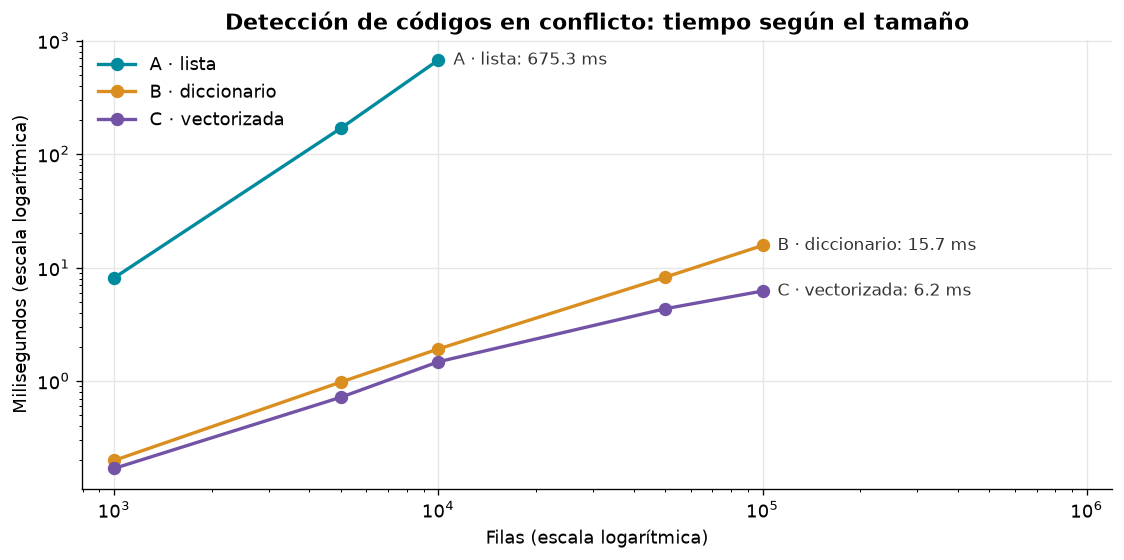

In [27]:
TAMANOS = [1000, 5000, 10000, 50000, 100000]
LIMITE_LISTA = 10000          # la versión cuadrática solo se mide hasta este tamaño

crecimiento = []
for n in TAMANOS:
    muestra = codigos_vigentes.sample(n=n, replace=True, random_state=SEMILLA)
    lista = (tiempo_minimo(lambda: conflictos_con_lista(muestra), repeticiones=3) * 1000
             if n <= LIMITE_LISTA else np.nan)
    diccionario = tiempo_minimo(lambda: conflictos_con_diccionario(muestra), repeticiones=7) * 1000
    vectorizada = tiempo_minimo(lambda: conflictos_vectorizado(muestra), repeticiones=7) * 1000
    crecimiento.append({"filas": n, "lista_ms": round(lista, 2), "diccionario_ms": round(diccionario, 2),
                        "vectorizada_ms": round(vectorizada, 2),
                        "razon_diccionario_vectorizada": round(diccionario / vectorizada, 2)})

tabla_crecimiento = pd.DataFrame(crecimiento)
print(tabla_crecimiento.to_string(index=False))

lista_5000, lista_10000 = tabla_crecimiento.set_index("filas").loc[[5000, 10000], "lista_ms"]
factor_lista = lista_10000 / lista_5000
print(f"\nVersión con lista: de 5.000 a 10.000 filas su tiempo se multiplica por {factor_lista:.1f}")
print(f"Estimación cuadrática para 100.000 filas: {lista_10000 * 100 / 1000:.0f} s (no se mide)")

# Gráfico: una línea por versión, con su valor final rotulado
DIR_FIGURAS_F3.mkdir(parents=True, exist_ok=True)
figura, eje = plt.subplots(figsize=(9.5, 4.8))
series = [("lista_ms", "A · lista"), ("diccionario_ms", "B · diccionario"), ("vectorizada_ms", "C · vectorizada")]
for (columna, etiqueta), color in zip(series, COLORES):
    puntos = tabla_crecimiento.dropna(subset=[columna])
    eje.plot(puntos["filas"], puntos[columna], marker="o", markersize=7, linewidth=2, color=color, label=etiqueta)
    ultimo = puntos.iloc[-1]
    eje.annotate(f"{etiqueta}: {ultimo[columna]:,.1f} ms", (ultimo["filas"], ultimo[columna]),
                 xytext=(9, 0), textcoords="offset points", va="center", fontsize=10, color="#333333")
eje.set_xscale("log")
eje.set_yscale("log")
eje.set_xlim(right=max(TAMANOS) * 12)                    # espacio para los rótulos
eje.set_xlabel("Filas (escala logarítmica)")
eje.set_ylabel("Milisegundos (escala logarítmica)")
eje.set_title("Detección de códigos en conflicto: tiempo según el tamaño")
eje.grid(True, which="major", color="#e6e6e6", linewidth=0.8)
eje.legend(frameon=False, loc="upper left")
figura.tight_layout()
figura.savefig(DIR_FIGURAS_F3 / "f3_01_crecimiento.png", bbox_inches="tight")
plt.show()

**Qué obtuvimos.** La tabla y el gráfico muestran dos comportamientos distintos. La versión con lista tiene la firma de
una complejidad cuadrática: al duplicar las filas su tiempo se multiplica aproximadamente por cuatro, su curva sube con
el doble de pendiente que las otras y, con 100.000 filas, tardaría del orden de un minuto. El diccionario y la versión
vectorizada crecen de forma aproximadamente lineal, pero no igual: la última columna de la tabla indica cuántas veces
más tarda el diccionario, y esa razón **aumenta en los tamaños mayores**, porque pandas cuenta en código compilado mientras el
diccionario recorre cada elemento en Python. En los tamaños más pequeños la diferencia entre ambas es mínima, porque
pandas tiene un costo fijo de preparación que solo se diluye con más datos.

**Decisión del grupo.** Descartamos la versión con lista, aunque es la más simple de escribir y la que menos memoria
usa: con un registro diez veces mayor tardaría cerca de cien veces más. Entre las otras dos elegimos la
**vectorizada**, que es la más rápida al tamaño real y la que mejor escala. Es la implementación que usa
`FiltroCodigosEnConflicto`.

### 15.4 ¿Dónde se concentra el tiempo del pipeline?
Antes de optimizar hay que saber dónde está el costo. Para eso usamos el observador `RegistroTiempos`, que anota la
duración de cada paso **mientras el pipeline se ejecuta**, sin modificar los pasos. Es el patrón Observer de la sección
8 aplicado a la medición: no tuvimos que instrumentar ninguna clase.

In [28]:
preprocesador_medido = PreprocesadorRegistro(CONFIGURACION)
_ = preprocesador_medido.ajustar_transformar(datos)

tiempos_f3 = preprocesador_medido.tiempos
tiempos_f3["porcentaje"] = (tiempos_f3["milisegundos"] / tiempos_f3["milisegundos"].sum() * 100).round(1)

print("Los seis pasos más costosos:")
print(tiempos_f3.sort_values("milisegundos", ascending=False).head(6).to_string(index=False))
print("\nTiempo por etapa:")
print(tiempos_f3.groupby("etapa", sort=False)[["milisegundos", "porcentaje"]].sum().round(1).to_string())

paso_mas_costoso = tiempos_f3.sort_values("milisegundos", ascending=False).iloc[0]
print(f"\nPaso más costoso: {paso_mas_costoso['paso']} ({paso_mas_costoso['porcentaje']} % del total)")

Los seis pasos más costosos:
                                          paso  filas_entrada  milisegundos       etapa  porcentaje
 normalizar_columna(TipoPertenenciaEstabGlosa)           5837        25.128 preparación        21.3
                   F03 FiltroDuplicadosExactos           5406        24.307   población        20.6
      normalizar_columna(EstadoFuncionamiento)           5837        10.419 preparación         8.8
                   F01 FiltroValoresPermitidos           5837         8.411   población         7.1
                           F06 FiltroInformado           5365         5.596   población         4.7
normalizar_columna(NivelComplejidadEstabGlosa)           5837         5.572 preparación         4.7

Tiempo por etapa:
              milisegundos  porcentaje
etapa                                 
preparación           52.4        44.3
población             61.2        51.8
codificación           4.3         3.7

Paso más costoso: normalizar_columna(TipoPertenenciaEsta

**Qué obtuvimos.** La mayor parte del tiempo está en la construcción de la población, con sus ocho filtros, seguida
por la preparación, que normaliza el texto de las 5.837 filas; la codificación es marginal. Los pasos más costosos son los que
recorren más texto: `F03`, que compara las 33 columnas originales para detectar filas repetidas, y las normalizaciones.
Ningún paso concentra por sí solo la mayor parte del tiempo.

**Decisión del grupo.** Como el costo está repartido, decidimos no reescribir ningún paso aislado: la ganancia sería
pequeña y tendríamos que volver a demostrar que el resultado no cambia. Buscamos la optimización en otro lugar: en
**cuántas veces se recorre el pipeline**, que es lo que medimos a continuación.

### 15.5 Antes y después: el costo de la arquitectura
Organizar el código en clases agrega llamadas, validaciones y copias defensivas. Además, la forma habitual de uso,
`ajustar(datos)` seguido de `transformar(datos)`, recorre el pipeline **dos veces**: una para aprender y otra para
aplicar. Cuando se aprende y se aplica sobre el mismo registro, `ajustar_transformar` hace lo mismo en **una sola
pasada**. Comparamos tres ejecuciones sobre el registro real, después de comprobar que dan el mismo resultado:

- **antes:** la función de la Fase 2 (sección 2);
- **después, en dos pasadas:** las clases con `ajustar` y luego `transformar`;
- **después, en una pasada:** las clases con `ajustar_transformar`.

El gráfico de barras muestra las tres con su tiempo y cuántas veces representa respecto de la Fase 2.

Las tres ejecuciones producen la misma población y la misma matriz.



,implementacion,milisegundos,memoria_pico_mb,veces_respecto_de_F2
0,F2 · función de referencia,76.6,8.90,1.0
1,"F3 · clases, dos pasadas",214.7,11.50,2.8
2,"F3 · clases, una pasada",99.6,10.96,1.3


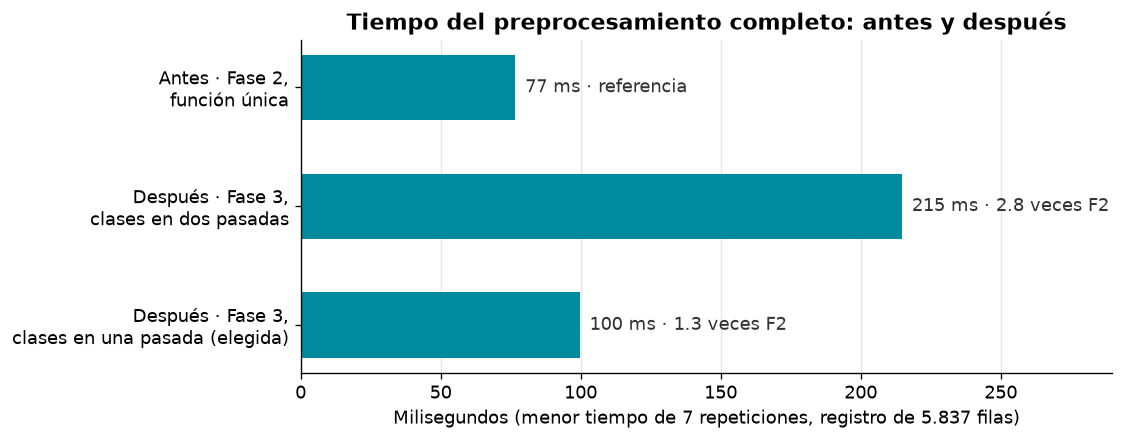

In [29]:
def ejecutar_dos_pasadas(datos_entrada):
    """Ajusta y después transforma: recorre el pipeline dos veces."""
    return PreprocesadorRegistro(CONFIGURACION).ajustar(datos_entrada).transformar(datos_entrada)


def ejecutar_una_pasada(datos_entrada):
    """Aprende y aplica en un solo recorrido."""
    return PreprocesadorRegistro(CONFIGURACION).ajustar_transformar(datos_entrada)


# Equivalencia antes de medir: las dos formas de F3 y la referencia de F2 dan lo mismo
una, dos = ejecutar_una_pasada(datos), ejecutar_dos_pasadas(datos)
for clave in ["poblacion", "matriz"]:
    pd.testing.assert_frame_equal(una[clave], dos[clave])
    pd.testing.assert_frame_equal(una[clave], referencia_f2[clave])
print("Las tres ejecuciones producen la misma población y la misma matriz.\n")

IMPLEMENTACIONES = [("F2 · función de referencia", flujo_f2), ("F3 · clases, dos pasadas", ejecutar_dos_pasadas),
                    ("F3 · clases, una pasada", ejecutar_una_pasada)]
filas = []
for nombre, funcion in IMPLEMENTACIONES:
    segundos = tiempo_minimo(lambda: funcion(datos), repeticiones=7)
    _, _, memoria = medir(funcion, datos)
    filas.append({"implementacion": nombre, "milisegundos": round(segundos * 1000, 1), "memoria_pico_mb": round(memoria, 2)})

costo_arquitectura = pd.DataFrame(filas)
tiempo_f2 = costo_arquitectura["milisegundos"].iloc[0]
costo_arquitectura["veces_respecto_de_F2"] = (costo_arquitectura["milisegundos"] / tiempo_f2).round(2)
display(costo_arquitectura)

# Gráfico: una barra por implementación, de la Fase 2 (arriba) a la forma elegida (abajo)
etiquetas = ["Antes · Fase 2,\nfunción única", "Después · Fase 3,\nclases en dos pasadas",
             "Después · Fase 3,\nclases en una pasada (elegida)"]
figura, eje = plt.subplots(figsize=(9.5, 3.8))
barras = eje.barh(etiquetas[::-1], costo_arquitectura["milisegundos"][::-1], color=COLORES[0], height=0.55)
rotulos = [f"{fila.milisegundos:.0f} ms · " + ("referencia" if fila.Index == 0 else f"{fila.veces_respecto_de_F2:.1f} veces F2")
           for fila in costo_arquitectura.itertuples()]
eje.bar_label(barras, labels=rotulos[::-1], padding=6, color="#333333")
eje.set_xlim(0, costo_arquitectura["milisegundos"].max() * 1.35)
eje.set_xlabel("Milisegundos (menor tiempo de 7 repeticiones, registro de 5.837 filas)")
eje.set_title("Tiempo del preprocesamiento completo: antes y después")
eje.grid(True, axis="x", color="#e6e6e6", linewidth=0.8)
eje.set_axisbelow(True)
figura.tight_layout()
figura.savefig(DIR_FIGURAS_F3 / "f3_02_costo_pipeline.png", bbox_inches="tight")
plt.show()

**Qué obtuvimos.** El gráfico responde la pregunta de cuánto cuesta el cambio. La arquitectura con clases tarda más
que la función de la Fase 2 y usa algo más de memoria: cada paso valida sus columnas, copia su entrada para no
modificarla y los filtros evalúan su condición al aprender y al aplicar. La ejecución en dos pasadas paga ese costo dos
veces, y por eso es la barra más larga. La ejecución en una pasada recupera buena parte de esa diferencia sin cambiar
el resultado, como confirma la comprobación de equivalencia del inicio de la celda; el porcentaje exacto de ahorro
queda en la bitácora de la sección 16 y en las conclusiones.

**Decisión del grupo.** Ejecutamos el preprocesamiento con `ajustar_transformar`, en una pasada, y reservamos
`transformar` para aplicar lo aprendido a un corte nuevo del registro. El costo que queda respecto de la Fase 2 lo
aceptamos como grupo, por dos razones. La primera es de magnitud: sigue siendo una fracción de segundo sobre el
registro completo, así que no afecta el uso real del proyecto. La segunda es lo que obtenemos a cambio: cada paso se
puede probar por separado, las reglas se declaran como datos y la bitácora se genera sola en cada ejecución.

### 15.6 Resumen: qué medimos, cuándo y qué decidimos
La tabla reúne las mediciones de esta ejecución con sus cifras y la decisión que tomamos a partir de cada una. Se
construye desde las variables medidas, de modo que siempre refleja la última ejecución del cuaderno y no puede quedar
desfasada respecto de las tablas anteriores.

In [30]:
t = medicion_real.set_index("version")["milisegundos"]
m = medicion_real.set_index("version")["memoria_pico_kb"]
c = costo_arquitectura.set_index("implementacion")
mayor = tabla_crecimiento.iloc[-1]

resumen_mediciones = pd.DataFrame([
    {"medicion": "Códigos en conflicto: tiempo al tamaño real",
     "cuando": f"15.2 · {len(codigos_vigentes)} códigos, tras comprobar equivalencia",
     "resultado": f"lista {t['A · lista']:.1f} ms · diccionario {t['B · diccionario']:.2f} ms · "
                  f"vectorizada {t['C · vectorizada']:.2f} ms",
     "decision": "Descartar la versión con lista"},
    {"medicion": "Códigos en conflicto: memoria pico",
     "cuando": "15.2 · misma ejecución, con tracemalloc",
     "resultado": f"lista {m['A · lista']:.0f} KB · diccionario {m['B · diccionario']:.0f} KB · "
                  f"vectorizada {m['C · vectorizada']:.0f} KB",
     "decision": "El tiempo decide: las tres usan kilobytes"},
    {"medicion": "Crecimiento con el tamaño",
     "cuando": "15.3 · muestras de 1.000 a 100.000 filas",
     "resultado": f"lista x{factor_lista:.1f} al duplicar filas · a {int(mayor['filas'])} filas: diccionario "
                  f"{mayor['diccionario_ms']:.1f} ms, vectorizada {mayor['vectorizada_ms']:.1f} ms",
     "decision": "La regla F04 usa la versión vectorizada"},
    {"medicion": "Tiempo de cada paso del pipeline",
     "cuando": "15.4 · durante la ejecución, con el observador",
     "resultado": f"paso más costoso: {paso_mas_costoso['paso']} ({paso_mas_costoso['porcentaje']} %)",
     "decision": "No reescribir un paso aislado"},
    {"medicion": "Pipeline completo, antes y después",
     "cuando": f"15.5 · registro real de {len(datos)} filas",
     "resultado": f"F2 {c.loc['F2 · función de referencia', 'milisegundos']:.0f} ms · dos pasadas "
                  f"{c.loc['F3 · clases, dos pasadas', 'milisegundos']:.0f} ms · una pasada "
                  f"{c.loc['F3 · clases, una pasada', 'milisegundos']:.0f} ms",
     "decision": "Ejecutar con ajustar_transformar (una pasada)"},
])

print(f"Mediciones del {MOMENTO_MEDICION:%d-%m-%Y %H:%M} · {EQUIPO}")
with pd.option_context("display.max_colwidth", None):
    display(resumen_mediciones)

Mediciones del 20-11-2026 22:56 · Linux 6.18.44-fc-v726 · x86_64 · Python 3.13.18


,medicion,cuando,resultado,decision
0,Códigos en conflicto: tiempo al tamaño real,"15.2 · 5406 códigos, tras comprobar equivalencia",lista 269.6 ms · diccionario 0.89 ms · vectorizada 0.39 ms,Descartar la versión con lista
1,Códigos en conflicto: memoria pico,"15.2 · misma ejecución, con tracemalloc",lista 43 KB · diccionario 152 KB · vectorizada 140 KB,El tiempo decide: las tres usan kilobytes
2,Crecimiento con el tamaño,15.3 · muestras de 1.000 a 100.000 filas,"lista x4.0 al duplicar filas · a 100000 filas: diccionario 15.7 ms, vectorizada 6.2 ms",La regla F04 usa la versión vectorizada
3,Tiempo de cada paso del pipeline,"15.4 · durante la ejecución, con el observador",paso más costoso: normalizar_columna(TipoPertenenciaEstabGlosa) (21.3 %),No reescribir un paso aislado
4,"Pipeline completo, antes y después",15.5 · registro real de 5837 filas,F2 77 ms · dos pasadas 215 ms · una pasada 100 ms,Ejecutar con ajustar_transformar (una pasada)


**Qué obtuvimos.** Cinco mediciones y cinco decisiones, cada una con el momento y las condiciones en que se midió. Para
que las mediciones fueran válidas seguimos tres reglas:

1. **Repetir y conservar el tiempo menor**, no el promedio.
2. **Medir sobre el tamaño real** (los códigos vigentes y las 5.837 filas del registro), además de la curva de
   crecimiento.
3. **Comprobar que las versiones dan el mismo resultado** antes de comparar su costo.

Los tiempos absolutos cambian de un equipo a otro, y por eso la tabla registra dónde se midió. Lo que se mantiene son
las **razones** entre versiones y la forma de la curva de crecimiento; nuestras decisiones se apoyan en esas razones y
no en un valor aislado.

---
## 16. Bitácora de decisiones de diseño
Registramos cada decisión de diseño de la fase con su motivo, la alternativa que descartamos y su efecto. Las dos
decisiones que vienen de las mediciones toman sus cifras de la sección 15, para que la bitácora coincida con lo que se
midió. La tabla se guarda en `docs/f3/bitacora_decisiones_f3.csv`.

In [31]:
razon_lista = t["A · lista"] / t["C · vectorizada"]
ahorro_pasada = (1 - c.loc["F3 · clases, una pasada", "milisegundos"] / c.loc["F3 · clases, dos pasadas", "milisegundos"]) * 100

bitacora_decisiones = pd.DataFrame([
    {"decision": "Usar clases solo en los componentes que recuerdan algo; el resto son funciones",
     "motivo": "Una clase se justifica cuando necesita guardar estado entre una llamada y otra",
     "alternativa_descartada": "Una clase por cada paso, incluida la normalización de texto",
     "efecto": f"{len(jerarquia)} clases y 3 funciones sin estado, integradas con el adaptador PasoFuncion"},
    {"decision": "Clase intermedia Filtro para las ocho reglas",
     "motivo": "Todas separan las filas excluidas y les asignan paso y motivo",
     "alternativa_descartada": "Repetir esa lógica en cada filtro",
     "efecto": "Cada filtro concreto implementa solo su condición"},
    {"decision": "Patrón Observer para bitácora, exclusiones y tiempos",
     "motivo": "En F2 cada filtro recibía y modificaba listas compartidas",
     "alternativa_descartada": "Seguir pasando las listas como argumentos",
     "efecto": "Los filtros no conocen la bitácora; el registro de tiempos se agregó sin tocarlos"},
    {"decision": "Patrón Factory para construir el pipeline desde las reglas",
     "motivo": "En F2 cada regla era una llamada escrita a mano",
     "alternativa_descartada": "Mantener las ocho llamadas en el flujo",
     "efecto": "Agregar o cambiar una regla es editar una línea de configuración"},
    {"decision": "No usar Strategy ni Singleton",
     "motivo": "No comparamos estrategias alternativas y la configuración ya es única",
     "alternativa_descartada": "Aplicar los cuatro patrones",
     "efecto": "Menos complejidad: solo los dos patrones que resuelven un problema real"},
    {"decision": "Regla F04 con la detección vectorizada",
     "motivo": "La medición mostró que la versión con lista crece de forma cuadrática",
     "alternativa_descartada": "Lista con count (la más simple) y diccionario",
     "efecto": f"{razon_lista:.0f} veces más rápida que la lista al tamaño real"},
    {"decision": "Ejecutar el preprocesamiento en una pasada",
     "motivo": "Ajustar y luego transformar recorre el pipeline dos veces",
     "alternativa_descartada": "Dos llamadas sobre el mismo registro",
     "efecto": f"{ahorro_pasada:.0f} % menos de tiempo, con el mismo resultado"},
    {"decision": "No reescribir pasos aislados",
     "motivo": f"El costo está repartido: el paso más costoso es el {paso_mas_costoso['porcentaje']} % del total",
     "alternativa_descartada": "Optimizar el filtro de duplicados exactos",
     "efecto": "Se evita el riesgo de alterar un resultado ya verificado contra F2"},
    {"decision": "Recursividad solo en la jerarquía de clases y la configuración anidada",
     "motivo": "Son las dos estructuras de profundidad variable del proyecto",
     "alternativa_descartada": "Recursión dentro del pipeline",
     "efecto": "El pipeline sigue siendo iterativo, más simple de leer"},
    {"decision": "Conservar el flujo de F2 como línea base y guardar las salidas de F3 aparte",
     "motivo": "Hace falta para verificar la equivalencia y medir el antes y el después",
     "alternativa_descartada": "Eliminar el flujo anterior o sobrescribir los archivos de F2",
     "efecto": "La comparación con F2 se puede repetir en cualquier momento"},
])
with pd.option_context("display.max_colwidth", None):
    display(bitacora_decisiones)

,decision,motivo,alternativa_descartada,efecto
0,Usar clases solo en los componentes que recuerdan algo; el resto son funciones,Una clase se justifica cuando necesita guardar estado entre una llamada y otra,"Una clase por cada paso, incluida la normalización de texto","10 clases y 3 funciones sin estado, integradas con el adaptador PasoFuncion"
1,Clase intermedia Filtro para las ocho reglas,Todas separan las filas excluidas y les asignan paso y motivo,Repetir esa lógica en cada filtro,Cada filtro concreto implementa solo su condición
2,"Patrón Observer para bitácora, exclusiones y tiempos",En F2 cada filtro recibía y modificaba listas compartidas,Seguir pasando las listas como argumentos,Los filtros no conocen la bitácora; el registro de tiempos se agregó sin tocarlos
3,Patrón Factory para construir el pipeline desde las reglas,En F2 cada regla era una llamada escrita a mano,Mantener las ocho llamadas en el flujo,Agregar o cambiar una regla es editar una línea de configuración
4,No usar Strategy ni Singleton,No comparamos estrategias alternativas y la configuración ya es única,Aplicar los cuatro patrones,Menos complejidad: solo los dos patrones que resuelven un problema real
5,Regla F04 con la detección vectorizada,La medición mostró que la versión con lista crece de forma cuadrática,Lista con count (la más simple) y diccionario,688 veces más rápida que la lista al tamaño real
6,Ejecutar el preprocesamiento en una pasada,Ajustar y luego transformar recorre el pipeline dos veces,Dos llamadas sobre el mismo registro,"54 % menos de tiempo, con el mismo resultado"
7,No reescribir pasos aislados,El costo está repartido: el paso más costoso es el 21.3 % del total,Optimizar el filtro de duplicados exactos,Se evita el riesgo de alterar un resultado ya verificado contra F2
8,Recursividad solo en la jerarquía de clases y la configuración anidada,Son las dos estructuras de profundidad variable del proyecto,Recursión dentro del pipeline,"El pipeline sigue siendo iterativo, más simple de leer"
9,Conservar el flujo de F2 como línea base y guardar las salidas de F3 aparte,Hace falta para verificar la equivalencia y medir el antes y el después,Eliminar el flujo anterior o sobrescribir los archivos de F2,La comparación con F2 se puede repetir en cualquier momento


**Qué obtuvimos.** La bitácora reúne diez decisiones. Cuatro son de diseño orientado a objetos (qué es clase y qué es
función, la clase intermedia y los dos patrones), una explica lo que decidimos **no** hacer (los patrones que no
aplican), tres provienen directamente de las mediciones de la sección 15 y dos tratan de recursividad y de
trazabilidad. Cada fila indica también la alternativa que descartamos, porque una decisión solo se entiende completa
cuando se sabe contra qué se comparó.

---
## 17. Arquitectura generada desde el propio código
En vez de escribir a mano la tabla de arquitectura, la generamos con la función recursiva de la sección 14 y la
completamos con los componentes que no son transformadores. El archivo de cada componente no se escribe: se obtiene
del módulo donde está definido, con `inspect`. Así la tabla refleja el código real.

In [32]:
from src import (carga, conflictos, descripcion, estructura, fabrica, funciones, medicion, observadores,
                 pipeline as modulo_pipeline, preprocesador as modulo_preprocesador)

OTROS_COMPONENTES = [
    (funciones.normalizar_columna, "función sin estado"), (funciones.agregar_fila_origen, "función sin estado"),
    (funciones.seleccionar_columnas, "función sin estado"),
    (modulo_pipeline.Pipeline, "orquestador"), (modulo_pipeline.PipelineObservable, "orquestador (Observer)"),
    (observadores.BitacoraFiltros, "observador"), (observadores.RegistroExclusiones, "observador"),
    (observadores.RegistroTiempos, "observador"),
    (fabrica.crear_filtro, "fábrica (Factory)"), (modulo_preprocesador.PreprocesadorRegistro, "fachada"),
    (conflictos.conflictos_vectorizado, "operación medida"), (descripcion.construir_contingencia, "función descriptiva"),
    (estructura.recorrer_jerarquia, "función recursiva"), (estructura.aplanar, "función recursiva"),
    (medicion.medir, "utilidad de medición"), (carga.cargar_registro, "carga"),
]


def documentar_arquitectura():
    """Tabla de componentes: la jerarquía se recorre de forma recursiva y el archivo se lee del módulo."""
    roles = {0: "clase base", 1: "clase hija", 2: "clase hija (segundo nivel)"}
    filas = [{"componente": fila["clase"], "rol": "clase intermedia" if fila["clase"] == "Filtro" else roles[fila["nivel"]],
              "responsabilidad": fila["descripcion"], "archivo": "src/transformadores.py"}
             for fila in recorrer_jerarquia(Transformador)]
    for objeto, rol in OTROS_COMPONENTES:
        filas.append({"componente": objeto.__name__, "rol": rol,
                      "responsabilidad": (objeto.__doc__ or "").strip().split("\n")[0],
                      "archivo": "src/" + Path(inspect.getsourcefile(objeto)).name})
    return pd.DataFrame(filas)


arquitectura = documentar_arquitectura()
with pd.option_context("display.max_colwidth", None):
    display(arquitectura)

,componente,rol,responsabilidad,archivo
0,Transformador,clase base,Clase base abstracta: contrato común y control de estado de cada paso del pipeline.,src/transformadores.py
1,PasoFuncion,clase hija,Adapta una función sin estado al contrato del pipeline.,src/transformadores.py
2,MapeadorCategorias,clase hija,Traduce etiquetas normalizadas a categorías analíticas con un mapeo explícito.,src/transformadores.py
3,Filtro,clase intermedia,Clase intermedia: conserva las filas que cumplen una condición.,src/transformadores.py
4,FiltroValoresPermitidos,clase hija (segundo nivel),Conserva las filas cuyo valor pertenece a un conjunto declarado.,src/transformadores.py
5,FiltroInformado,clase hija (segundo nivel),Conserva las filas con valor presente y no vacío.,src/transformadores.py
6,FiltroValorExcluido,clase hija (segundo nivel),"Excluye las filas que tienen un valor explícito, como «no aplica».",src/transformadores.py
7,FiltroDuplicadosExactos,clase hija (segundo nivel),Conserva una copia de las filas repetidas en todas las columnas indicadas.,src/transformadores.py
8,FiltroCodigosEnConflicto,clase hija (segundo nivel),Excluye todos los registros de un código que aparece más de una vez.,src/transformadores.py
9,CodificadorBinario,clase hija,Crea un indicador 0/1 por categoría declarada (codificación One-Hot).,src/transformadores.py


**Qué obtuvimos.** La tabla muestra los 26 componentes principales del sistema: las 10 clases de la jerarquía de
transformación y 16 componentes de apoyo, entre funciones sin estado, orquestadores, observadores, la fábrica, la
fachada y las utilidades, cada uno con su responsabilidad y su archivo. Como la responsabilidad se lee de la
documentación de cada pieza y el archivo se obtiene del propio módulo, la tabla no puede quedar desactualizada. La
estructura del proyecto queda así:

```
grupo1-proyecto-mcdi500/
├── F1/  F2/                 fases anteriores
├── F3/                      este cuaderno, ejecutado
├── src/                     el código: 14 módulos, uno por responsabilidad
├── tests/                   30 pruebas del núcleo, con un comando
├── data/raw/                archivo original, sin modificar
├── data/processed/          salidas de F2 y, en f3/, salidas de esta fase
├── docs/                    documentación de F1 y F2 y, en f3/, la de esta fase
├── ejecutar_proyecto.py     ejecuta F1, F2 y F3 en orden
└── requirements.txt         dependencias con versión fija
```

---
## 18. Persistencia y verificación final contra la Fase 2
Guardamos los resultados en carpetas propias de la fase (`data/processed/f3` y `docs/f3`), sin sobrescribir las
salidas de la Fase 2. Además de los conjuntos, guardamos los parámetros que aprendió cada paso, la bitácora de
decisiones y las mediciones de la sección 15, que permiten reproducir o auditar el resultado.

In [33]:
def guardar_resultados_f3(carpeta_datos=DIR_SALIDA_F3, carpeta_docs=DIR_DOCS_F3):
    """Escribe los resultados de la fase y devuelve sus rutas."""
    carpeta_datos.mkdir(parents=True, exist_ok=True)
    carpeta_docs.mkdir(parents=True, exist_ok=True)
    tablas = {
        carpeta_datos / "poblacion_f3.csv": (poblacion_f3, False),
        carpeta_datos / "matriz_f3.csv": (matriz_f3, False),
        carpeta_datos / "clave_filas_f3.csv": (clave_filas_f3, False),
        carpeta_datos / "contingencia_f3.csv": (tabla_contingencia_f3, True),
        carpeta_datos / "porcentajes_f3.csv": (porcentajes_f3, True),
        carpeta_docs / "bitacora_filtros_f3.csv": (tabla_filtros_f3, False),
        carpeta_docs / "exclusiones_f3.csv": (exclusiones_f3[COLUMNAS_AUDITORIA], False),
        carpeta_docs / "parametros_f3.csv": (preprocesador.parametros(), False),
        carpeta_docs / "bitacora_decisiones_f3.csv": (bitacora_decisiones, False),
        carpeta_docs / "arquitectura_f3.csv": (arquitectura, False),
        carpeta_docs / "mediciones_resumen_f3.csv": (resumen_mediciones, False),
        carpeta_docs / "medicion_conflictos_f3.csv": (medicion_real, False),
        carpeta_docs / "crecimiento_f3.csv": (tabla_crecimiento, False),
        carpeta_docs / "tiempos_por_paso_f3.csv": (tiempos_f3, False),
        carpeta_docs / "costo_pipeline_f3.csv": (costo_arquitectura, False),
    }
    for ruta, (tabla, indice) in tablas.items():
        tabla.to_csv(ruta, index=indice, encoding="utf-8-sig")
    metadatos = {"fase": 3, "filas_originales": len(datos), "filas_poblacion": len(poblacion_f3),
                 "filas_excluidas": len(exclusiones_f3), "columnas_matriz": COLUMNAS_NUMERICAS,
                 "identico_a_f2": bool(verificacion["idéntico"].all()), "sha256_original": METADATOS_F1["sha256"],
                 "patrones": ["Observer", "Factory"], "pruebas": pruebas_normales + pruebas_limite + pruebas_error,
                 "medicion": {"momento": MOMENTO_MEDICION.isoformat(timespec="minutes"), "equipo": EQUIPO},
                 "configuracion_f1": configuracion_plana}
    (carpeta_docs / "metadatos_f3.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")
    return list(tablas) + [carpeta_docs / "metadatos_f3.json"]


guardados = guardar_resultados_f3()
print("RESULTADOS DE LA FASE 3")
for ruta in guardados:
    print(f"  {ruta.relative_to(RAIZ).as_posix():<42} {ruta.stat().st_size / 1024:>7.1f} KB")

RESULTADOS DE LA FASE 3
  data/processed/f3/poblacion_f3.csv           245.4 KB
  data/processed/f3/matriz_f3.csv               45.0 KB
  data/processed/f3/clave_filas_f3.csv          74.4 KB
  data/processed/f3/contingencia_f3.csv          0.1 KB
  data/processed/f3/porcentajes_f3.csv           0.2 KB
  docs/f3/bitacora_filtros_f3.csv                0.5 KB
  docs/f3/exclusiones_f3.csv                   170.2 KB
  docs/f3/parametros_f3.csv                      1.9 KB
  docs/f3/bitacora_decisiones_f3.csv             2.2 KB
  docs/f3/arquitectura_f3.csv                    3.3 KB
  docs/f3/mediciones_resumen_f3.csv              0.9 KB
  docs/f3/medicion_conflictos_f3.csv             0.2 KB
  docs/f3/crecimiento_f3.csv                     0.2 KB
  docs/f3/tiempos_por_paso_f3.csv                1.2 KB
  docs/f3/costo_pipeline_f3.csv                  0.2 KB
  docs/f3/metadatos_f3.json                      7.4 KB


**Qué obtuvimos.** Se escribieron 16 archivos, y las salidas de la Fase 2 no se tocaron.

| Archivos | Contenido |
|---|---|
| `poblacion_f3.csv`, `matriz_f3.csv` y `clave_filas_f3.csv` | Población de análisis, matriz 0/1 y su correspondencia con el registro |
| `contingencia_f3.csv` y `porcentajes_f3.csv` | Tabla de contingencia 2 × 3 y porcentajes por fila |
| `bitacora_filtros_f3.csv`, `exclusiones_f3.csv` y `parametros_f3.csv` | Lo necesario para reproducir o auditar la población |
| `bitacora_decisiones_f3.csv` y `arquitectura_f3.csv` | Decisiones de diseño y componentes del sistema |
| `mediciones_resumen_f3.csv`, `medicion_conflictos_f3.csv`, `crecimiento_f3.csv`, `tiempos_por_paso_f3.csv` y `costo_pipeline_f3.csv` | Mediciones de tiempo y memoria de la sección 15 |
| `metadatos_f3.json` | Contexto de la ejecución y de la medición |

Los dos gráficos de la sección 15 quedaron en `docs/f3/figuras`.

### Verificación final contra la Fase 2
Cerramos con la comprobación más directa: leemos desde el disco el conjunto que entregó la Fase 2 y el que acaba de
guardar la Fase 3, y exigimos que sean iguales. Lo hacemos para la población y para la matriz, y agregamos cinco
controles de consistencia.

In [34]:
poblacion_guardada_f2 = pd.read_csv(DIR_PROCESADO / "poblacion_analisis.csv", dtype="string")
poblacion_guardada_f3 = pd.read_csv(DIR_SALIDA_F3 / "poblacion_f3.csv", dtype="string")
matriz_guardada_f2 = pd.read_csv(DIR_PROCESADO / "matriz_numerica_0_1.csv")
matriz_guardada_f3 = pd.read_csv(DIR_SALIDA_F3 / "matriz_f3.csv")

assert poblacion_guardada_f3.equals(poblacion_guardada_f2), "El pipeline de la Fase 3 cambió la población"
assert matriz_guardada_f3.equals(matriz_guardada_f2), "El pipeline de la Fase 3 cambió la matriz"
assert matriz_f3.equals(matriz_guardada_f2), "El pipeline de la Fase 3 cambió el resultado"
print("Población guardada en F3 == población entregada en F2:", poblacion_guardada_f3.shape)
print("Matriz guardada en F3    == matriz entregada en F2   :", matriz_guardada_f3.shape, "\n")

controles = pd.DataFrame([
    {"control": "Se conservan todas las filas", "cumple": len(poblacion_f3) + len(exclusiones_f3) == len(datos),
     "detalle": f"{len(poblacion_f3)} + {len(exclusiones_f3)} = {len(datos)}"},
    {"control": "Códigos únicos en la población", "cumple": bool(poblacion_f3["codigo_establecimiento"].is_unique),
     "detalle": f"{len(poblacion_f3)} códigos"},
    {"control": "Sin faltantes", "cumple": not poblacion_f3.isna().any().any(), "detalle": "población y matriz"},
    {"control": "Matriz binaria con una categoría por variable",
     "cumple": bool(matriz_f3.isin([0, 1]).all().all() and matriz_f3.sum(axis=1).eq(2).all()), "detalle": str(matriz_f3.shape)},
    {"control": "Las nueve salidas de F2 se reproducen", "cumple": bool(verificacion["idéntico"].all()),
     "detalle": f"{int(verificacion['idéntico'].sum())} de {len(verificacion)}"},
])
print(controles.to_string(index=False))
assert controles["cumple"].all(), "Alguna comprobación final falló"
print("\nVERIFICACIÓN FINAL CORRECTA: el resultado de la Fase 3 es exactamente el de la Fase 2.")

Población guardada en F3 == población entregada en F2: (4603, 5)
Matriz guardada en F3    == matriz entregada en F2   : (4603, 5) 

                                      control  cumple            detalle
                 Se conservan todas las filas    True 4603 + 1234 = 5837
               Códigos únicos en la población    True       4603 códigos
                                Sin faltantes    True población y matriz
Matriz binaria con una categoría por variable    True          (4603, 5)
        Las nueve salidas de F2 se reproducen    True             9 de 9

VERIFICACIÓN FINAL CORRECTA: el resultado de la Fase 3 es exactamente el de la Fase 2.


**Qué obtuvimos.** Los archivos guardados por la Fase 3 son iguales a los que entregó la Fase 2: la población de
4.603 filas y la matriz de 4.603 × 5 coinciden al leerlas desde el disco, y la matriz que entrega el pipeline en
memoria es igual al archivo de la Fase 2. Los
cinco controles de consistencia también se cumplen. Con esto la fase queda cerrada con la misma garantía con que
partió: el pipeline reorganizado produce exactamente el mismo conjunto procesado.

---
## 19. Conclusiones y proyección a la Fase 4
Redactamos las conclusiones de tiempo y eficiencia con las cifras medidas en la sección 15. La celda siguiente las arma
a partir de las variables de esta ejecución, para que el texto y las tablas no puedan contradecirse; después
desarrollamos la lectura que hacemos como grupo.

In [35]:
tiempo_lista, tiempo_dicc, tiempo_vect = (t[nombre] for nombre, _ in VERSIONES)
dos_pasadas = c.loc["F3 · clases, dos pasadas", "milisegundos"]
una_pasada = c.loc["F3 · clases, una pasada", "milisegundos"]
referencia = c.loc["F2 · función de referencia", "milisegundos"]
memoria_f2 = c.loc["F2 · función de referencia", "memoria_pico_mb"]
memoria_f3 = c.loc["F3 · clases, una pasada", "memoria_pico_mb"]

conclusion = f"""
**Resultados medidos el {MOMENTO_MEDICION:%d-%m-%Y a las %H:%M} · {EQUIPO}**

1. **Detección de códigos en conflicto (regla F04).** Sobre {len(codigos_vigentes)} códigos vigentes, la versión con
   lista tardó {tiempo_lista:.1f} ms; la del diccionario, {tiempo_dicc:.2f} ms; y la vectorizada, {tiempo_vect:.2f} ms.
   La versión con lista fue {tiempo_lista / tiempo_vect:.0f} veces más lenta que la vectorizada, y al pasar de 5.000 a
   10.000 filas su tiempo se multiplicó por {factor_lista:.1f}, lo esperable en un costo cuadrático. **Decidimos**
   descartar la versión con lista y usar la vectorizada.
2. **Memoria.** La versión de menor memoria pico fue «{m.idxmin()}» ({m.min():.0f} KB) y la de mayor,
   «{m.idxmax()}» ({m.max():.0f} KB). La más rápida no fue la más liviana, pero todas usan kilobytes.
   **Decidimos** que el criterio para elegir fuera el tiempo.
3. **Escalabilidad.** Con {int(mayor['filas'])} filas, el diccionario tardó {mayor['diccionario_ms']:.1f} ms y la
   versión vectorizada, {mayor['vectorizada_ms']:.1f} ms: {mayor['razon_diccionario_vectorizada']:.1f} veces más rápida.
   **Decidimos** mantener la versión vectorizada, cuya ventaja crece con el tamaño del registro.
4. **Dónde se gasta el tiempo.** El paso más costoso fue {paso_mas_costoso['paso']}, con el
   {paso_mas_costoso['porcentaje']} % del tiempo del pipeline; el resto se reparte entre los demás pasos.
   **Decidimos** no reescribir ningún paso aislado.
5. **Antes y después.** Sobre las {len(datos)} filas del registro, la función de la Fase 2 tardó {referencia:.0f} ms;
   el pipeline con clases, {dos_pasadas:.0f} ms en dos pasadas y {una_pasada:.0f} ms en una pasada
   ({(1 - una_pasada / dos_pasadas) * 100:.0f} % menos). La memoria pico pasó de {memoria_f2:.1f} MB a {memoria_f3:.1f} MB.
   **Decidimos** ejecutar el preprocesamiento con `ajustar_transformar`, en una pasada, y aceptar el costo restante
   respecto de la Fase 2 ({una_pasada / referencia:.1f} veces en tiempo).
"""
display(Markdown(conclusion))


**Resultados medidos el 20-11-2026 a las 22:56 · Linux 6.18.44-fc-v726 · x86_64 · Python 3.13.18**

1. **Detección de códigos en conflicto (regla F04).** Sobre 5406 códigos vigentes, la versión con
   lista tardó 269.6 ms; la del diccionario, 0.89 ms; y la vectorizada, 0.39 ms.
   La versión con lista fue 688 veces más lenta que la vectorizada, y al pasar de 5.000 a
   10.000 filas su tiempo se multiplicó por 4.0, lo esperable en un costo cuadrático. **Decidimos**
   descartar la versión con lista y usar la vectorizada.
2. **Memoria.** La versión de menor memoria pico fue «A · lista» (43 KB) y la de mayor,
   «B · diccionario» (152 KB). La más rápida no fue la más liviana, pero todas usan kilobytes.
   **Decidimos** que el criterio para elegir fuera el tiempo.
3. **Escalabilidad.** Con 100000 filas, el diccionario tardó 15.7 ms y la
   versión vectorizada, 6.2 ms: 2.5 veces más rápida.
   **Decidimos** mantener la versión vectorizada, cuya ventaja crece con el tamaño del registro.
4. **Dónde se gasta el tiempo.** El paso más costoso fue normalizar_columna(TipoPertenenciaEstabGlosa), con el
   21.3 % del tiempo del pipeline; el resto se reparte entre los demás pasos.
   **Decidimos** no reescribir ningún paso aislado.
5. **Antes y después.** Sobre las 5837 filas del registro, la función de la Fase 2 tardó 77 ms;
   el pipeline con clases, 215 ms en dos pasadas y 100 ms en una pasada
   (54 % menos). La memoria pico pasó de 8.9 MB a 11.0 MB.
   **Decidimos** ejecutar el preprocesamiento con `ajustar_transformar`, en una pasada, y aceptar el costo restante
   respecto de la Fase 2 (1.3 veces en tiempo).


### Lo que concluimos como grupo

**Qué cambió y qué no.** Nuestro pipeline pasó de celdas y funciones con listas compartidas a un núcleo algorítmico
organizado en módulos: una clase base, una clase intermedia y ocho clases hijas, tres funciones sin estado, tres
pipelines construidos desde la configuración, observadores y una fachada. Los datos no cambiaron: las nueve salidas de
la Fase 2 se reproducen carácter por carácter, y lo comprobamos tres veces, en memoria, contra los archivos y al cierre.
Para nosotros ese es el resultado principal de la fase, porque nos permite afirmar que todo lo que sigue es una mejora
de la forma y no una alteración del análisis.

**Sobre el tiempo.** Las mediciones nos llevaron a tres decisiones que no habríamos tomado sin medir.

- *La implementación de la regla F04.* La forma más natural de escribirla, contando cada código en una lista, resultó
  cientos de veces más lenta que la vectorizada y con un crecimiento cuadrático, que la vuelve inviable para registros
  más grandes. Elegimos la versión vectorizada porque fue la más rápida al tamaño real y la que mejor escala.
- *No optimizar pasos aislados.* El tiempo por paso nos mostró que el costo está repartido y que ningún paso domina.
  Reescribir uno habría significado poco ahorro y el riesgo de alterar un resultado ya verificado, así que decidimos
  no hacerlo.
- *Ejecutar en una pasada.* La comparación del antes y el después nos mostró que la mayor ganancia disponible no
  estaba dentro de ningún paso, sino en no recorrer el pipeline dos veces. Con `ajustar_transformar` el tiempo baja
  en la proporción que muestra el punto 5, con el mismo resultado.

**Sobre la memoria.** Tiempo y memoria no apuntaron a la misma versión: la implementación más lenta fue la más
liviana. Como las diferencias de memoria fueron de kilobytes y las de tiempo de órdenes de magnitud, acordamos que el
tiempo fuera el criterio. Dejamos registrado que esta conclusión depende del volumen: con un registro mucho mayor
habría que volver a medir la memoria antes de decidir.

**Sobre el costo de la arquitectura.** Reconocemos que el pipeline con clases es más lento y usa más memoria que la
función de la Fase 2: la orientación a objetos no nos hizo ganar velocidad. Lo aceptamos como grupo porque el costo se
mantiene en una fracción de segundo sobre el registro completo y porque a cambio obtuvimos lo que la Fase 2 no tenía:
cada paso se puede probar por separado (30 pruebas), las reglas se declaran como datos, la bitácora se genera sola en
cada ejecución y lo aprendido se puede aplicar a un corte nuevo del registro. Nuestra conclusión es que, para este
proyecto, la mantenibilidad vale más que esos milisegundos, y que la eficiencia se cuidó donde realmente importaba.

**Límite de estas conclusiones.** Los tiempos absolutos dependen del equipo en que se ejecute el cuaderno. Lo que
sostenemos son las razones entre versiones y la forma en que crece el costo, que se mantienen de una máquina a otra.



| Concepto | Dónde se ve en este cuaderno |
|---|---|
| Código en una sola versión | El cuaderno importa todo desde `src/` y lo muestra con `mostrar_codigo` |
| Encapsulamiento | `_parametros`, `_ajustado`, `_excluidos`, propiedades de solo lectura y copias defensivas (secciones 3 y 4) |
| Abstracción | `Transformador` y `Filtro` son clases abstractas (`ABC` y `@abstractmethod`): no se pueden crear sin implementar su contrato (sección 3) |
| Herencia | Dos niveles: `Transformador` → `Filtro` → cinco filtros; `PipelineObservable` extiende `Pipeline` con `super()` (secciones 5 y 8) |
| Polimorfismo | `Pipeline` recorre funciones adaptadas y clases con la misma llamada (sección 7) |
| Patrones | Observer para la bitácora, las exclusiones y los tiempos; Factory para construir el pipeline desde las reglas (secciones 8 y 9) |
| Cohesión y acoplamiento | Un módulo por responsabilidad; agregar una variable no modifica ningún archivo de `src/` (sección 12) |
| Verificación | Igualdad con la Fase 2 en memoria, contra los archivos y al cierre (secciones 11 y 18) |
| Validación | Caso normal sobre el registro real y 30 pruebas de casos normales, límite y excepciones (sección 13) |
| Recursividad | Jerarquía de clases y configuración anidada, de profundidad variable (sección 14) |
| Eficiencia | `timeit`, `tracemalloc`, curva de crecimiento, tiempo por paso y antes/después, con dos gráficos (sección 15) |

### Proyección a la Fase 4
Esta fase reorganizó y midió el código sin agregar análisis nuevos; la evaluación estadística de la asociación
corresponde a la Fase 4, que parte de lo que queda guardado en `data/processed/f3`:

- La tabla de contingencia 2 × 3 permite aplicar una prueba de independencia chi-cuadrado y medir la magnitud de la
  asociación con la V de Cramér, previa revisión de las frecuencias esperadas.
- Antes de concluir examinaremos la relación por **tipo de establecimiento**, que puede explicar parte de la
  diferencia observada. La sección 12 mostró que incorporar esa variable requiere solo un cambio de configuración.
- El preprocesamiento no se repetirá a mano: importaremos `PreprocesadorRegistro` desde `src/` y lo ejecutaremos en
  una pasada, como decidimos en la sección 15.
- Se mantiene la limitación detectada en la Fase 2: la complejidad está disponible para el 99,00 % de los
  establecimientos SNSS vigentes y solo para el 67,78 % de los No SNSS, por lo que las conclusiones se limitarán a la
  población con complejidad informada.

  ## Referencia: retroalimentación del foro de reflexión de la Fase 1

Aporte de Kattia Espinoza Reyes (13-11-2026) y retroalimentación del profesor Omar Salinas Silva (15-11-2026).
El profesor señaló tres puntos para profundizar. Su estado en esta fase es el siguiente:

| # | Observación del foro | Estado en la Fase 3 |
|---|---|---|
| 1 | Al agregar SciPy, fijar su versión en `requirements.txt`. | **Pendiente para F4.** La Fase 3 no agrega dependencias: reorganiza el pipeline sin cambiar el análisis. SciPy se agregará con versión fija cuando F4 implemente la prueba, y la comparación de F1 §3.1 exigirá que el entorno coincida. |
| 2 | Revisar las frecuencias esperadas antes de chi-cuadrado y acompañar el valor p con la V de Cramér. | **Planificado para F4.** Tras el foro, la prueba de independencia se trasladó de "F3–F4" a F4, que incluirá la revisión de condiciones, la V de Cramér y el análisis por tipo de establecimiento (F1, plan de análisis; F2 §4). |
| 3 | Identificar qué filtro explica la menor retención de los No SNSS. | **Avance parcial.** La Fase 3 calcula la retención desde el registro de exclusiones del observador y reproduce las cifras de F2: 99,00 % SNSS frente a 67,78 % No SNSS. Las 731 exclusiones No SNSS ocurren en los filtros de complejidad (F06–F08). El desglose por filtro y grupo queda pendiente para la interpretación de F4. |

Se mantienen las prácticas destacadas en el foro: la configuración en `docs/proyecto.json`, que F3 vuelve a leer,
la verificación de la huella SHA-256 del CSV al cargar, y el trabajo en ramas integradas mediante pull requests.

## Bibliografía (APA 7)

Gamma, E., Helm, R., Johnson, R., & Vlissides, J. (1994). *Design patterns: Elements of reusable object-oriented
software*. Addison-Wesley.

McKinney, W. (2022). *Python for data analysis: Data wrangling with pandas, NumPy, and Jupyter* (3.ª ed.). O'Reilly
Media. https://wesmckinney.com/book/

Python Software Foundation. (s. f.-a). *Classes*. Python documentation. https://docs.python.org/3/tutorial/classes.html

Python Software Foundation. (s. f.-b). *timeit — Measure execution time of small code snippets*. Python documentation.
https://docs.python.org/3/library/timeit.html

Python Software Foundation. (s. f.-c). *tracemalloc — Trace memory allocations*. Python documentation.
https://docs.python.org/3/library/tracemalloc.html

Python Software Foundation. (s. f.-d). *unittest — Unit testing framework*. Python documentation.
https://docs.python.org/3/library/unittest.html

The pandas development team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/

---
*Avance Fase 3 · Semana 2 · Grupo 1 · MCDI500 · Universidad Andrés Bello*